# Proyecto final — Clasificación de arritmias cardiacas a partir de la derivación II del ECG

**Bioseñales y Sistemas — Universidad de Antioquia, 2026-2**

Mariana Giraldo Gil · Valentina García Obando

**Objetivo.** Clasificar cuatro ritmos cardiacos (bradicardia sinusal, ritmo sinusal, fibrilación auricular y taquicardia supraventricular generalizada) a partir de la derivación II de registros de la base de Chapman–Shaoxing [1], siguiendo el flujo de filtrado y la estrategia de características de Zheng et al. [2], y comparar modelos supervisados (redes neuronales, XGBoost y SVM) y no supervisados (K-means).

**Estructura del notebook.**
1. Revisión teórica de la extracción de características.
2. Selección de la muestra y lectura de la derivación II.
3. Filtrado de las señales (Butterworth, LOESS robusto y Non-Local Means) y su validación.
4. Extracción y justificación de las características.
5. y 6. Redes neuronales con 4 y 2 clases.
7. XGBoost y comparación con la mejor red.
8. K-means y SVM.
9. Informe: equipos comerciales, discusión, conclusiones y referencias.

## 1. Revisión teórica: extracción de características

La extracción de características constituye una etapa fundamental en los sistemas de clasificación de señales electrocardiográficas (ECG), debido a que permite representar las propiedades relevantes de la señal mediante variables que posteriormente pueden utilizarse en modelos de aprendizaje automático. En el artículo *Optimal Multi-Stage Arrhythmia Classification Approach*, Zheng et al. [2] discuten diferentes estrategias utilizadas para representar la información electrocardiográfica, incluyendo el aprendizaje de características mediante redes neuronales y la extracción tradicional de características morfológicas.

Entre las características morfológicas convencionalmente utilizadas se encuentran las magnitudes de los picos, sus duraciones, las distancias entre ellos y la variabilidad de dichas medidas. Estas características se obtienen a partir de los componentes principales del electrocardiograma, incluyendo la onda P, la onda Q, la onda T y el complejo QRS. Sin embargo, los autores señalan que este tipo de representación puede resultar insuficiente para lograr una clasificación precisa de determinados tipos de arritmias, particularmente aquellas en las que algunas estructuras de la señal presentan deformaciones o desaparecen completamente.

Un ejemplo mencionado en el artículo corresponde a la fibrilación auricular (AFIB) y al flutter auricular (AFL). En estas condiciones, las ondas P pueden ser reemplazadas por múltiples ondas de fibrilación o flutter, las cuales presentan amplitudes inferiores a las de una onda P normal y no mantienen una correspondencia regular con los complejos QRS. Esta alteración dificulta la identificación de las ondas auriculares y limita la utilidad de características que dependen directamente de su detección, medición de amplitud, duración o separación temporal.

Por lo tanto, cuando determinadas formas de onda no se encuentran claramente definidas, la extracción tradicional de características morfológicas puede perder información relevante o producir medidas inconsistentes entre registros. Asimismo, los autores señalan que las características obtenidas mediante transformadas Wavelet o Fourier pueden omitir información del dominio temporal, lo cual constituye otra limitación cuando se pretende caracterizar señales con comportamientos variables y estructuras morfológicas alteradas.

En consecuencia, el artículo destaca la necesidad de utilizar representaciones de la señal que permitan capturar información relevante para la diferenciación de las arritmias, sin depender exclusivamente de la identificación individual de componentes morfológicos que pueden estar deformados o ausentes. Esta consideración resulta especialmente importante en el desarrollo de sistemas automatizados de clasificación electrocardiográfica, debido a que las alteraciones propias de las patologías pueden modificar la estructura convencional de las ondas del ECG.

### 1.1 Características utilizadas para la representación de señales ECG

La extracción de características de una señal electrocardiográfica permite transformar la información contenida en la señal original en un conjunto de variables cuantificables que facilitan la identificación de patrones asociados a diferentes condiciones cardíacas. Tradicionalmente, esta extracción se basa en la identificación y medición de componentes morfológicos del ECG, tales como las ondas P, Q, R, S y T, así como los segmentos e intervalos que se encuentran entre ellos.

Entre las características convencionales se encuentran la amplitud, duración, prominencia y posición temporal de los picos y valles, además de medidas como el intervalo RR, el intervalo QT y la duración del complejo QRS. Estas características permiten describir tanto la morfología de cada ciclo cardíaco como las relaciones temporales entre diferentes eventos eléctricos.

Zheng et al. [2], en el artículo *Optimal Multi-Stage Arrhythmia Classification Approach*, proponen una estrategia de extracción de características basada en la medición de propiedades de los picos y valles de la señal ECG y en el análisis de las relaciones entre estas propiedades y sus posiciones temporales. En lugar de depender exclusivamente de medidas aisladas de las ondas, los autores estudian las relaciones entre pares de picos y valles, considerando diferencias en altura, ancho, prominencia y posición temporal.

Esta aproximación permite generar características que representan la distribución de las propiedades morfológicas de la señal y sus relaciones, proporcionando una descripción más amplia del comportamiento electrocardiográfico.

### 1.2 Estrategia de extracción de características propuesta por Zheng et al.

El método propuesto por Zheng et al. [2] utiliza las propiedades morfológicas de los picos y valles identificados en la señal ECG. Para ello, los autores agrupan los elementos de la señal en tres conjuntos: complejos QRS, picos diferentes al QRS y valles.

Posteriormente, consideran seis combinaciones de comparación entre estos conjuntos:

- QRS con QRS.
- Picos no-QRS con picos no-QRS.
- Valles con valles.
- QRS con picos no-QRS.
- QRS con valles.
- Picos no-QRS con valles.

Para cada combinación, se analizan las diferencias de altura, ancho y prominencia de los elementos, así como las diferencias en sus posiciones temporales. A partir de estas mediciones, se calculan relaciones entre las diferencias morfológicas y las diferencias temporales, con el propósito de representar cómo cambian las características de los picos y valles a lo largo de la señal.

Debido a que cada registro puede contener un número diferente de picos y valles, estas relaciones no generan directamente un vector de características de longitud fija. Para solucionar este problema, los autores construyen distribuciones empíricas de frecuencia de las características y sus relaciones, organizando los valores en 100 intervalos entre el valor mínimo y máximo observado.

De esta manera, la frecuencia de aparición de cada intervalo se convierte en una característica de entrada para los modelos de clasificación. Esta estrategia permite obtener una representación de longitud fija, independientemente del número de picos y valles identificados en cada registro.

El enfoque propuesto busca representar no solamente las magnitudes y dimensiones individuales de los elementos del ECG, sino también las relaciones que existen entre sus características morfológicas y sus posiciones temporales. Esto permite construir una representación más completa del comportamiento de la señal y facilita su utilización en algoritmos de aprendizaje automático.

**Detalles del método de Zheng et al. [2] que se tienen en cuenta en este trabajo:**
- **Prominencia.** Mide cuánto sobresale un pico (o valle) respecto a sus vecinos: es la distancia vertical entre el pico y la línea de contorno más baja que lo separa de un pico más alto. A diferencia de la altura, no depende de la línea de base.
- **Grupos de características.** Los autores compararon 11 conjuntos de características, desde uno simple con 11 variables hasta uno con 39 830. El *Feature Group 1* son 11 medidas que entrega el propio electrocardiógrafo (frecuencia ventricular y auricular, duración del QRS, intervalo QT, ejes R y T, número de QRS, inicio y fin del QRS, entre otras). El *Feature Group 2* son 23 variables de la derivación II: media, varianza y número de los intervalos RR, y media y varianza de la altura, el ancho y la prominencia de los picos QRS, los picos no-QRS y los valles.
- **Edad y sexo.** Los autores los añadieron como características "por su importancia en casi todos los análisis de datos médicos".
- **Reescalado.** Como la amplitud del ECG varía con el sexo, la edad y la etnia, reescalaron las señales con el método máximo-mínimo para unificar la escala de amplitud, y evaluaron su efecto en la clasificación.

En este proyecto se usa una versión del *Feature Group 2* (calculable solo con la derivación II), ampliada con características de ritmo y de ondas ausentes (punto 4). No se usan la edad, el sexo ni las medidas del electrocardiógrafo, para que la clasificación dependa solo de la señal.

### 1.3 Alteraciones morfológicas y ausencia de ondas en el ECG

Una de las dificultades en la extracción de características electrocardiográficas es que las estructuras morfológicas convencionales no siempre se encuentran claramente definidas. Algunas arritmias pueden modificar la forma, amplitud, duración o posición temporal de las ondas, e incluso generar la ausencia de componentes que normalmente se identifican en un ciclo cardíaco.

En el artículo de Zheng et al. [2], se menciona que en condiciones como la fibrilación auricular (AFIB) y el flutter auricular (AFL), las ondas P pueden ser reemplazadas por múltiples ondas de fibrilación o flutter. Estas ondas presentan amplitudes inferiores a las de una onda P normal y no necesariamente mantienen una relación temporal regular con los complejos QRS.

En estas condiciones, la identificación convencional de la onda P puede resultar difícil o incluso no ser posible. Por lo tanto, las características que dependen directamente de la detección de dicha onda, como su amplitud, duración o intervalo respecto al complejo QRS, pueden resultar inconsistentes o no estar disponibles.

Esta situación representa una limitación para los métodos de extracción de características que dependen de la identificación explícita de cada componente morfológico del ECG. En consecuencia, es importante utilizar estrategias que permitan representar las características globales de la señal y las relaciones entre sus diferentes elementos, incluso cuando algunas ondas no presentan una morfología convencional.

### 1.4 Limitaciones de los métodos tradicionales y justificación de la estrategia

La variabilidad morfológica de las señales electrocardiográficas constituye uno de los principales retos para la construcción de sistemas automatizados de clasificación. Las características de las ondas pueden cambiar entre individuos y dentro de un mismo individuo, además de verse afectadas por alteraciones cardíacas, ruido y diferencias en las condiciones de adquisición.

En el artículo analizado, los autores señalan que algunas estrategias basadas en transformadas Wavelet o Fourier pueden presentar limitaciones cuando se pretende conservar información del dominio temporal. Esto resulta relevante debido a que el ECG es una señal cuya morfología y comportamiento temporal pueden variar durante el registro.

Por esta razón, Zheng et al. proponen una estrategia que combina la identificación de picos y valles con la caracterización de sus magnitudes, dimensiones y relaciones temporales. La construcción de distribuciones empíricas de estas variables permite obtener un conjunto de características de longitud fija que puede utilizarse en sistemas de clasificación.

La estrategia busca reducir la dependencia de medidas aisladas de ondas específicas y representar de manera más amplia las características de la señal. Sin embargo, el método sigue dependiendo de la detección y caracterización de los picos y valles, por lo que la calidad del procesamiento previo y la identificación de estos elementos continúa siendo importante.

### 1.5 Aplicación de la revisión teórica al presente proyecto

A partir de la revisión del artículo, se considera importante construir un conjunto de características que permita representar diferentes aspectos de la señal ECG y que no dependa exclusivamente de la presencia de ondas P claramente identificables.

Para el presente proyecto, se utilizará la derivación II de los registros electrocardiográficos seleccionados y previamente filtrados. Se buscará combinar las características estudiadas en el Proyecto 1 con características morfológicas relacionadas con la altura, ancho, prominencia y posición temporal de los picos y valles, así como con relaciones entre estas variables.

Esta selección busca proporcionar una representación de la señal que permita diferenciar las cuatro clases de estudio: bradicardia sinusal (SB), fibrilación auricular (AFIB), ritmo sinusal (SR) y taquicardia supraventricular generalizada (GSVT).

La revisión teórica también justifica la importancia de realizar un procesamiento previo de las señales, debido a que la presencia de ruido o de fluctuaciones de línea base puede afectar la identificación de los elementos morfológicos y, por tanto, la calidad de las características posteriormente utilizadas en los modelos de clasificación.

## 2. Selección de la muestra y lectura de la derivación II

In [113]:
import os, time, zipfile, warnings
from pathlib import Path, PurePosixPath
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy.signal import butter, buttord, sosfiltfilt, filtfilt, find_peaks
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# ------------------------- RUTAS -------------------------
RUTA_DIAGNOSTICOS_COMPLETO = "Diagnostics.xlsx"          # solo si hay que rehacer la muestra
RUTA_ECG_ZIP               = "ECGData.zip"               # solo si hay que rehacer la muestra
RUTA_DENOISED_ZIP          = "ECGDataDenoised.zip"       # base del Proyecto 1 (para validar el filtrado)
CARPETA_ECG                = "ECGData_muestra"           # CSV crudos de la muestra (12 derivaciones)
RUTA_DIAGNOSTICOS          = "Diagnostics_muestra_2000.csv"
CARPETA_DENOISED_VAL       = "ECGDenoised_validacion"    # se llena sola con unos pocos registros
CARPETA_DENOISED_LOCAL     = os.path.join("..", "Proyecto", "ChapmanECG", "ECGDataDenoised")  # señales filtradas del Proyecto 1
CARPETA_CACHE              = "cache"

# ------------------------- PARÁMETROS -------------------------
FS               = 500        # Hz
MUESTRAS         = 5000       # 10 s
DERIVACION_II    = 1          # índice de la columna de la derivación II
N_JOBS           = -1         # -1 = todos los núcleos
SEMILLA          = 42
N_CLASES         = 4          # SB, SR, AFIB y GSVT; la taquicardia sinusal (ST) se excluye del estudio
PAR_BINARIO      = ("SR", "AFIB")   # punto 6: las dos clases elegidas (de las 4)
USAR_EDAD_SEXO   = False      # True: añade edad y sexo como características (como Zheng et al.)
USAR_ATRIB_MUSE  = False      # True: añade las medidas del electrocardiógrafo (VentricularRate, QTInterval, ...)
RECALCULAR       = False      # True: ignora la caché y recalcula todo

# Parámetros del filtrado (punto 3). Los de LOESS y NLM ya están sintonizados contra la señal del Proyecto 1 (sección 3.4)
LOESS_FRAC  = 0.10    # fracción de la señal usada en cada ajuste local
LOESS_GRADO = 2       # grado del polinomio local (2 = LOESS clásico de Cleveland)
NLM_H      = 4.0      # suavizado NLM (múltiplo del ruido estimado)

Path(CARPETA_CACHE).mkdir(exist_ok=True)
def cache(nombre): return os.path.join(CARPETA_CACHE, nombre)
print("Núcleos disponibles:", os.cpu_count())

Núcleos disponibles: 12


### 2.1 Selección de la muestra

**Criterios.** Se seleccionaron 2000 registros de la base de Chapman [1]: **500 por cada una de cuatro clases de ritmo**, todos de pacientes **adultos (18 años o más)**. Cada clase se muestrea por separado con la misma semilla (`SEMILLA = 42`), de modo que la selección es reproducible. Los ritmos originales de la base se agrupan como en Zheng et al. [2]:

| Clase | Ritmos de la base incluidos |
|---|---|
| **SB**: bradicardia sinusal | SB |
| **SR**: ritmo sinusal | SR (ritmo sinusal) y SA (arritmia sinusal) |
| **AFIB**: fibrilación auricular | AFIB (fibrilación auricular) y AF (flutter auricular) |
| **GSVT**: taquicardia supraventricular generalizada | SVT, AT, AVNRT, AVRT y SAAWR |

**¿Por qué se excluyó la taquicardia sinusal (ST)?** La ST es un ritmo de origen **sinusal**: cada QRS va precedido de una onda P normal, y solo se diferencia del ritmo sinusal normal en la frecuencia (> 100 lpm). Los ritmos agrupados en GSVT, en cambio, se originan **fuera del nodo sinusal** (aurícula o unión auriculoventricular). Unir ST con GSVT mezclaría dos mecanismos fisiológicos distintos en una misma clase. Además, ST y GSVT tienen frecuencias parecidas, y como nuestras características dependen sobre todo del ritmo (intervalos RR), el clasificador las confundiría por construcción y no por una falla del modelo. Por eso se trabajó con cuatro clases de mecanismo homogéneo. Esta definición de GSVT coincide con la de Zheng et al. [2], que describen el grupo como taquicardia supraventricular, taquicardia auricular, taquicardia por reentrada nodal, taquicardia por reentrada auriculoventricular y marcapasos auricular migratorio, sin incluir la taquicardia sinusal.

**Limitación:** al excluir la ST, el modelo no fue entrenado para reconocerla. Un registro de taquicardia sinusal real sería asignado a alguna de las cuatro clases, muy probablemente a GSVT o a SR.

**¿Por qué una muestra balanceada?** Con el mismo número de registros por clase, ningún modelo puede obtener buen desempeño favoreciendo la clase más frecuente, y la exactitud y el F1 macro se interpretan igual. El costo es que la muestra no refleja la frecuencia real de cada arritmia en la población.

In [114]:
GRUPO_RITMO = {"SB": "SB", "AFIB": "AFIB", "AF": "AFIB",
               "SVT": "GSVT", "AT": "GSVT", "AVNRT": "GSVT", "AVRT": "GSVT", "SAAWR": "GSVT",
               "SR": "SR", "SA": "SR", "ST": "ST"}
ORDEN_5 = ["SB", "SR", "AFIB", "GSVT", "ST"]

def crear_muestra(edad_min=18, n_por_grupo=500):
    diag = pd.read_excel(RUTA_DIAGNOSTICOS_COMPLETO)
    diag["FileName"] = diag["FileName"].astype(str).str.strip()
    diag["Grupo"] = diag["Rhythm"].map(GRUPO_RITMO)
    assert diag["Grupo"].notna().all(), "Hay ritmos sin grupo"
    diag["PatientAge"] = pd.to_numeric(diag["PatientAge"], errors="coerce")
    # Adultos (>= 18 años) y sin taquicardia sinusal (ST), que se excluye del estudio
    adultos = diag[(diag["PatientAge"] >= edad_min) & (diag["Grupo"] != "ST")]
    # Cada grupo se muestrea por separado con la misma semilla, así la selección es reproducible
    muestra = pd.concat([g.sample(n=n_por_grupo, random_state=SEMILLA) for _, g in adultos.groupby("Grupo")])
    muestra["Grupo"] = pd.Categorical(muestra["Grupo"], categories=ORDEN_5, ordered=True)
    muestra = muestra.sort_values(["Grupo", "FileName"]).reset_index(drop=True)
    os.makedirs(CARPETA_ECG, exist_ok=True)
    with zipfile.ZipFile(RUTA_ECG_ZIP) as z:
        indice = {PurePosixPath(n).stem: n for n in z.namelist() if n.lower().endswith(".csv")}
        faltan = []
        for nombre in muestra["FileName"]:
            base = os.path.splitext(nombre)[0]
            if base not in indice: faltan.append(nombre); continue
            destino = os.path.join(CARPETA_ECG, base + ".csv")
            if not os.path.exists(destino):
                with open(destino, "wb") as f: f.write(z.read(indice[base]))
    muestra.to_csv(RUTA_DIAGNOSTICOS, index=False, encoding="utf-8-sig")
    print(f"Muestra creada: {len(muestra)} registros; no encontrados en el zip: {len(faltan)}")

if not (os.path.isdir(CARPETA_ECG) and os.path.isfile(RUTA_DIAGNOSTICOS)):
    crear_muestra()
else:
    print("La muestra ya existe: no se rehace.")

La muestra ya existe: no se rehace.


### 2.2 Verificación y selección de clases

In [115]:
diag = pd.read_csv(RUTA_DIAGNOSTICOS)
diag["FileName"] = diag["FileName"].astype(str).str.replace(r"\.csv$", "", regex=True)

# Etiqueta de trabajo: la muestra ya no contiene ST (se excluyó al crearla); las clases son SB, SR, AFIB y GSVT
diag["Estado"] = diag["Grupo"]                                   # grupo original de cada registro
diag["Clase"]  = diag["Grupo"].replace({"ST": "GSVT"}) if N_CLASES == 4 else diag["Grupo"]
CLASES = [c for c in ORDEN_5 if c in diag["Clase"].unique()]

archivos = {p.stem for p in Path(CARPETA_ECG).glob("*.csv")}
print("Registros clínicos:", len(diag), "| señales en carpeta:", len(archivos))
print("Sin señal:", len(set(diag["FileName"]) - archivos), "| señales sin diagnóstico:", len(archivos - set(diag["FileName"])))
print("\nClases de trabajo:", CLASES)
display(pd.crosstab(diag["Estado"], diag["Clase"]))

Registros clínicos: 2000 | señales en carpeta: 2000
Sin señal: 0 | señales sin diagnóstico: 0

Clases de trabajo: ['SB', 'SR', 'AFIB', 'GSVT']


Clase,AFIB,GSVT,SB,SR
Estado,,,,
AFIB,500,0,0,0
GSVT,0,500,0,0
SB,0,0,500,0
SR,0,0,0,500


### 2.3 Lectura de la derivación II y características demográficas

In [116]:
def _tiene_encabezado(ruta):
    with open(ruta, "r") as f:
        tok = f.readline().split(",")[0].strip()
    try: float(tok); return False
    except ValueError: return True

def leer_derivacion_ii(nombre, carpeta=CARPETA_ECG, col=DERIVACION_II):
    ruta = os.path.join(carpeta, nombre + ".csv")
    enc = _tiene_encabezado(ruta)
    x = pd.read_csv(ruta, header=0 if enc else None, usecols=[col], dtype=np.float32).iloc[:, 0].to_numpy()
    return x

def cargar_matriz(nombres, carpeta=CARPETA_ECG):
    señales = Parallel(n_jobs=N_JOBS, batch_size=16)(delayed(leer_derivacion_ii)(n, carpeta) for n in nombres)
    malos = [n for n, s in zip(nombres, señales) if len(s) != MUESTRAS]
    if malos: print(f"AVISO: {len(malos)} registros no tienen {MUESTRAS} muestras (se descartarán): {malos[:5]}")
    return señales, malos

t0 = time.perf_counter()
_cache_ok = (os.path.exists(cache("lead2_cruda.npy")) and os.path.exists(cache("nombres.npy")) and not RECALCULAR)
if _cache_ok:
    _nombres_cache = list(np.load(cache("nombres.npy"), allow_pickle=True))
    _cache_ok = set(_nombres_cache) <= set(diag["FileName"])          # la caché debe corresponder a esta muestra
if _cache_ok:
    X_cruda = np.load(cache("lead2_cruda.npy")); nombres_ok = _nombres_cache
else:
    señales, malos = cargar_matriz(diag["FileName"].tolist())
    nombres_ok = [n for n, s in zip(diag["FileName"], señales) if len(s) == MUESTRAS]
    X_cruda = np.vstack([s for s in señales if len(s) == MUESTRAS]).astype(np.float32)
    np.save(cache("lead2_cruda.npy"), X_cruda); np.save(cache("nombres.npy"), np.array(nombres_ok, dtype=object))

diag = diag.set_index("FileName").loc[nombres_ok].reset_index()
print(f"Matriz de derivación II: {X_cruda.shape}, {X_cruda.nbytes/1e6:.0f} MB, lista en {time.perf_counter()-t0:.1f} s")
print("Valores NaN:", int(np.isnan(X_cruda).sum()), "| registros planos:", int((np.ptp(X_cruda, axis=1) == 0).sum()))

Matriz de derivación II: (2000, 5000), 40 MB, lista en 0.0 s
Valores NaN: 0 | registros planos: 0


In [117]:
# ---------- Caracterización demográfica de la muestra ----------
edad = pd.to_numeric(diag["PatientAge"], errors="coerce")
print(f"Edad: {edad.mean():.2f} ± {edad.std():.2f} años | mediana {edad.median():.0f} | rango {edad.min():.0f}–{edad.max():.0f}")
print("Sexo:", {"hombres": int((diag["Gender"] == "MALE").sum()), "mujeres": int((diag["Gender"] == "FEMALE").sum())})

# Por clase: permite ver si alguna arritmia tiene pacientes de otra edad o sexo (posible sesgo)
demo = (diag.assign(Edad=edad)
            .groupby("Clase")
            .agg(edad_media=("Edad", "mean"), edad_de=("Edad", "std"), edad_mediana=("Edad", "median"),
                 hombres=("Gender", lambda g: int((g == "MALE").sum())),
                 mujeres=("Gender", lambda g: int((g == "FEMALE").sum())))
            .loc[CLASES].round(1))
display(demo)

Edad: 60.99 ± 16.92 años | mediana 63 | rango 18–96
Sexo: {'hombres': 1052, 'mujeres': 948}


,edad_media,edad_de,edad_mediana,hombres,mujeres
Clase,,,,,
SB,59.4,13.9,61.0,314,186
SR,53.3,16.2,54.0,205,295
AFIB,72.8,12.3,74.5,289,211
GSVT,58.4,18.2,59.0,244,256


## Punto 2. Análisis: base de datos y muestra

**Control de calidad.** Se verificó que los 2000 registros clínicos tuvieran su archivo de señal, y viceversa (0 faltantes en ambos sentidos), que todas las señales tuvieran 5000 muestras (10 s a 500 Hz), que no hubiera valores faltantes en la derivación II y que ningún registro fuera una señal plana. Todos los registros pasaron el control, así que no fue necesario descartar ninguno.

**Características demográficas.** La muestra tiene una edad media de 60,99 ± 16,92 años (mediana de 63, rango de 18 a 96 años) y está compuesta por 1052 hombres (52,6 %) y 948 mujeres (47,4 %). Por clase:

| Clase | Edad media ± DE | Mediana | Hombres | Mujeres |
|---|---|---|---|---|
| SB | 59,4 ± 13,9 | 61 | 314 (63 %) | 186 (37 %) |
| SR | 53,3 ± 16,2 | 54 | 205 (41 %) | 295 (59 %) |
| AFIB | 72,8 ± 12,3 | 74,5 | 289 (58 %) | 211 (42 %) |
| GSVT | 58,4 ± 18,2 | 59 | 244 (49 %) | 256 (51 %) |

**Diferencias entre clases.** Los pacientes con fibrilación auricular son en promedio **casi 20 años mayores** que los de ritmo sinusal (72,8 frente a 53,3 años). Esto es coherente con la epidemiología: la prevalencia de la fibrilación auricular aumenta con la edad [3]. También hay diferencias de sexo: la bradicardia sinusal es más frecuente en hombres (63 %), mientras que en ritmo sinusal predominan las mujeres (59 %).

**¿Por qué importa?** Estas diferencias son un posible **factor de confusión**. La edad modifica el ECG por sí misma (por ejemplo, la variabilidad del ritmo cardiaco disminuye con los años), así que parte de lo que un modelo aprende para separar AFIB de SR podría estar asociado a la edad del paciente y no solo a la arritmia. En este trabajo la edad y el sexo **no se usaron como características** (`USAR_EDAD_SEXO = False`), así que los modelos no tienen acceso directo a ellas, pero sí pueden verse afectados de forma indirecta. Una forma de controlarlo sería emparejar las clases por edad al seleccionar la muestra.

**Balance de clases.** Con 500 registros por clase, ningún modelo puede obtener buen desempeño favoreciendo la clase más frecuente. Como contrapartida, la muestra no refleja la frecuencia real de las arritmias: en la práctica, la fibrilación auricular es mucho menos común que el ritmo sinusal. Por eso los resultados de clasificación deben interpretarse para esta muestra, y no como el desempeño esperado en una población general.

## 3. Filtrado de las señales

Las señales crudas tienen tres tipos de perturbación: **ruido de alta frecuencia** (actividad muscular, interferencia electrónica), **deriva de la línea de base** (respiración, movimiento de los electrodos; por debajo de ~0,5 Hz) y **ruido residual** de banda ancha. Zheng et al. [1] los eliminan con tres etapas en serie, que se implementan aquí con NumPy y SciPy.

**Etapa 1: filtro Butterworth pasa-bajas** [4]. Su respuesta en magnitud es

$$|H(j\omega)|^2=\frac{1}{1+\left(\omega/\omega_c\right)^{2n}}$$

donde $n$ es el orden y $\omega_c$ la frecuencia de corte. Es *máximamente plano* en la banda de paso: no tiene rizado, así que no deforma las ondas del ECG. Las especificaciones del artículo son: banda de paso hasta 50 Hz con rizado ≤ 1 dB, y banda de rechazo desde 60 Hz con atenuación ≥ 2,5 dB. La función `buttord` calcula el orden mínimo que las cumple: **orden 3, con frecuencia de corte de 61,5 Hz**. El filtro se aplica hacia adelante y hacia atrás (`sosfiltfilt`): así la fase se cancela y las ondas no se desplazan en el tiempo; como efecto secundario, la atenuación en dB se duplica.

**Etapa 2: LOESS robusto (resta de la línea de base)** [5]. Para cada punto $x_0$ se ajusta un polinomio de grado 2 por mínimos cuadrados ponderados, usando solo una ventana de vecinos (`LOESS_FRAC` = 10 % de la señal = 1 s). Los vecinos pesan según su distancia, con el **kernel tricúbico**:

$$w_i=\left(1-\left|\frac{t_i-t_0}{d_{max}}\right|^3\right)^3$$

El valor del polinomio en $x_0$ es la estimación de la línea de base. La versión **robusta** repite el ajuste 3 veces y, en cada repetición, baja el peso de los puntos con residuo grande $e_i$ usando pesos **bicuadrados**:

$$r_i=\left(1-\left(\frac{e_i}{6\,\text{MAD}}\right)^2\right)^2 \text{ si } |e_i|<6\,\text{MAD}, \quad r_i=0 \text{ en otro caso}$$

donde MAD es la mediana de los residuos absolutos. Sin esta corrección, los complejos QRS, que son picos grandes y rápidos, "jalarían" la línea de base hacia arriba. La línea de base estimada se **resta** de la señal.

**Etapa 3: Non-Local Means (NLM)** [6], [7]. Cada muestra $i$ se reemplaza por un promedio ponderado de las muestras $j$ cercanas (±100 muestras = ±0,2 s), donde el peso depende de cuánto se parece el **parche** alrededor de $j$ (11 muestras) al parche alrededor de $i$:

$$\hat x(i)=\frac{\sum_j w(i,j)\,x(j)}{\sum_j w(i,j)},\qquad w(i,j)=\exp\!\left(-\frac{\sum_{\delta}\left[x(i+\delta)-x(j+\delta)\right]^2}{2L\,\lambda^2}\right)$$

$L = 11$ es el tamaño del parche y $\lambda = h\,\hat\sigma$ controla cuánto se suaviza. $\hat\sigma$ es el nivel de ruido estimado de forma robusta a partir de la mediana de las diferencias entre muestras consecutivas, y $h$ = `NLM_H` = 4. La idea es que una porción de un QRS solo se promedia con porciones que también parecen QRS, así que el ruido baja **sin aplanar los picos**, cosa que sí haría un filtro pasa-bajas más fuerte.

**Eficiencia.** Filtrar 2000 señales de 5000 muestras con implementaciones directas tomaría horas. El LOESS se evalúa en una malla de 200 puntos (cada 25 muestras) y se interpola; los 200 ajustes se resuelven a la vez como sistemas pequeños por lotes. El NLM recorre cada desplazamiento posible y calcula la diferencia de parches de todas las muestras a la vez con sumas acumuladas. Así, un registro se filtra en unas decenas de milisegundos.

### 3.1 Implementación de las tres etapas

La siguiente celda define una función por etapa (`butterworth_pb`, `loess_robusto` y `nlm_1d`) y la función `filtrar`, que las aplica en serie: Butterworth → resta de la línea de base → NLM.

In [118]:
# ---------- 1) Butterworth pasa-bajas ----------
ORDEN_BW, WN_BW = buttord(wp=50, ws=60, gpass=1.0, gstop=2.5, fs=FS)
SOS_BW = butter(ORDEN_BW, WN_BW, btype="low", fs=FS, output="sos")
print(f"Butterworth: orden {ORDEN_BW}, frecuencia de corte {WN_BW:.1f} Hz")

def butterworth_pb(x):
    return sosfiltfilt(SOS_BW, x)

# ---------- 2) LOESS robusto (línea de base) ----------
def loess_robusto(x, frac=LOESS_FRAC, grado=LOESS_GRADO, paso=25, n_iter=3, k_mad=6.0):
    # Tendencia estimada por LOESS robusto, evaluada en una malla cada `paso` muestras e interpolada.
    n = len(x); q = int(np.ceil(frac * n))
    centros = np.unique(np.r_[np.arange(0, n, paso), n - 1])
    inicio = np.clip(centros - q // 2, 0, n - q)
    idx = inicio[:, None] + np.arange(q)[None, :]                    # (M, q) vecinos de cada centro
    d = (idx - centros[:, None]).astype(np.float64)
    h = np.maximum(np.abs(d).max(axis=1), 1)                         # ancho de banda local
    u = d / h[:, None]
    w_dist = (1 - np.abs(u) ** 3) ** 3                               # kernel tricúbico
    xv = x[idx]
    pot = [np.ones_like(u)]
    for _ in range(2 * grado): pot.append(pot[-1] * u)               # u^0 ... u^(2·grado)
    w_rob = np.ones(n)
    for _ in range(n_iter):
        w = w_dist * w_rob[idx]
        S = np.stack([(w * p).sum(axis=1) for p in pot], axis=1)                 # momentos Σ w·u^k
        T = np.stack([(w * pot[k] * xv).sum(axis=1) for k in range(grado + 1)], axis=1)
        A = S[:, np.add.outer(np.arange(grado + 1), np.arange(grado + 1))] + 1e-9 * np.eye(grado + 1)
        ajuste = np.linalg.solve(A, T[..., None])[..., 0][:, 0]      # valor del ajuste en el centro (u = 0)
        tendencia = np.interp(np.arange(n), centros, ajuste)
        res = x - tendencia
        mad = np.median(np.abs(res))
        if mad == 0: break
        r = res / (k_mad * mad)
        w_rob = np.where(np.abs(r) < 1, (1 - r ** 2) ** 2, 0.0)      # pesos bicuadrados, 0 fuera de 6 MAD
    return tendencia

# ---------- 3) Non-Local Means ----------
def nlm_1d(x, mitad_parche=5, mitad_busqueda=100, h=NLM_H):
    n = len(x); L = 2 * mitad_parche + 1
    dx = np.diff(x)
    sigma = 1.4826 * np.median(np.abs(dx - np.median(dx))) / np.sqrt(2)   # ruido estimado (MAD de la derivada)
    lam2 = max(h * sigma, 1e-6) ** 2
    p = mitad_busqueda + mitad_parche
    xp = np.pad(x, (p, p), mode="reflect")
    base = xp[p - mitad_parche : p + n + mitad_parche]
    num = np.zeros(n); den = np.zeros(n)
    for d in range(-mitad_busqueda, mitad_busqueda + 1):
        otro = xp[p + d - mitad_parche : p + d + n + mitad_parche]
        cs = np.concatenate(([0.0], np.cumsum((base - otro) ** 2)))
        dist_parche = (cs[L:] - cs[:-L]) / L                         # media de (D(i+δ)-D(j+δ))² en el parche
        w = np.exp(-dist_parche / (2 * lam2))
        num += w * xp[p + d : p + d + n]; den += w
    return num / den

def filtrar(x, frac=None, h=None):
    # Flujo completo: Butterworth -> LOESS (resta de línea de base) -> NLM.
    frac = LOESS_FRAC if frac is None else frac
    h = NLM_H if h is None else h
    x = np.asarray(x, dtype=np.float64)
    y = butterworth_pb(x)
    y = y - loess_robusto(y, frac=frac)
    return nlm_1d(y, h=h)

Butterworth: orden 3, frecuencia de corte 61.5 Hz


### 3.2 Prueba del flujo en un registro y tiempo por etapa

Se aplica el flujo a un registro de ritmo sinusal y se grafica la señal después de cada etapa, para comprobar visualmente qué hace cada una.

{'Butterworth': '2.3 ms', 'LOESS robusto': '18.2 ms', 'NLM': '23.7 ms'} | total 44 ms por registro


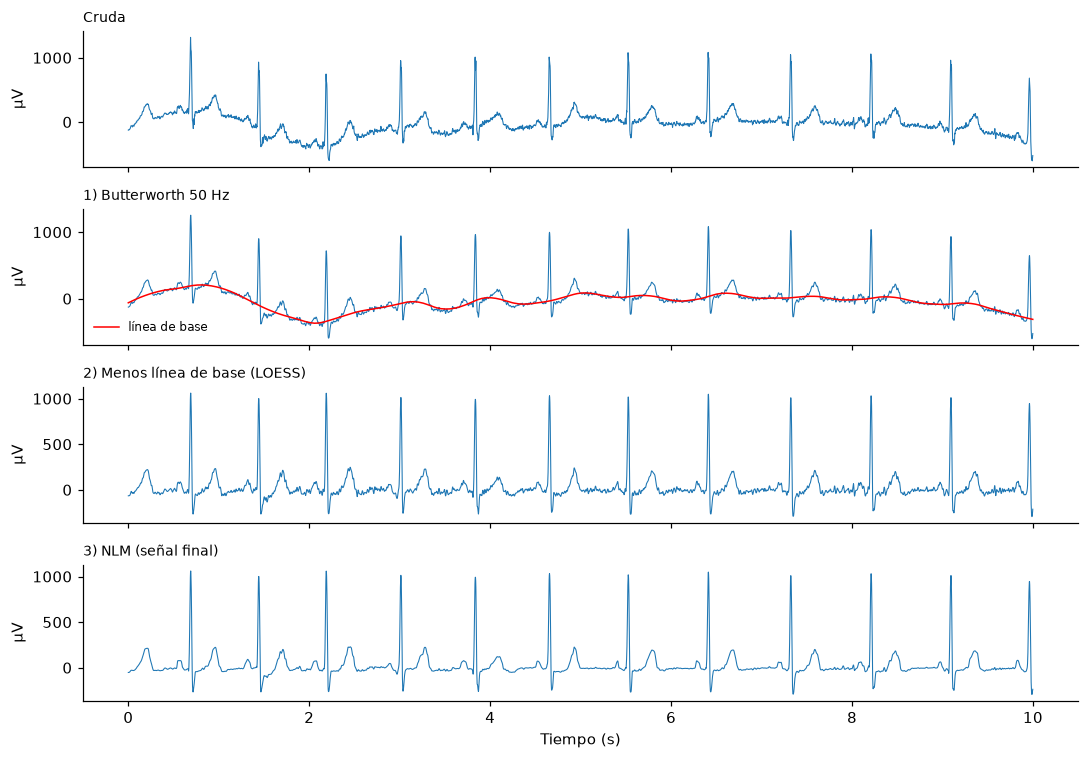

In [119]:
i_ej = int(np.where(diag["Estado"].values == "SR")[0][0])
x = X_cruda[i_ej].astype(float)
t = np.arange(MUESTRAS) / FS

tiempos = {}
t0 = time.perf_counter(); y1 = butterworth_pb(x);              tiempos["Butterworth"] = time.perf_counter() - t0
t0 = time.perf_counter(); base = loess_robusto(y1);            tiempos["LOESS robusto"] = time.perf_counter() - t0
y2 = y1 - base
t0 = time.perf_counter(); y3 = nlm_1d(y2);                     tiempos["NLM"] = time.perf_counter() - t0
print({k: f"{1000*v:.1f} ms" for k, v in tiempos.items()}, f"| total {1000*sum(tiempos.values()):.0f} ms por registro")

fig, ax = plt.subplots(4, 1, figsize=(10, 7), sharex=True)
for a, s, tit in zip(ax, [x, y1, y2, y3], ["Cruda", "1) Butterworth 50 Hz", "2) Menos línea de base (LOESS)", "3) NLM (señal final)"]):
    a.plot(t, s, lw=0.7); a.set_title(tit, loc="left", fontsize=9); a.set_ylabel("µV")
ax[1].plot(t, base, "r", lw=1, label="línea de base"); ax[1].legend(frameon=False, fontsize=8)
ax[-1].set_xlabel("Tiempo (s)"); plt.tight_layout(); plt.show()

### 3.3 Validación contra la señal filtrada del Proyecto 1

La base de Chapman incluye una versión ya filtrada de cada registro (`ECGDataDenoised`), obtenida por los autores con el flujo original [1]; es la que se usó en el Proyecto 1. Se toman 20 registros (5 por clase, elegidos al azar con la semilla) y se compara la señal filtrada con nuestro flujo ($x$) contra esa referencia ($r$), con tres métricas:

$$\text{RMSE}=\sqrt{\frac{1}{N}\sum_{n=1}^{N}\big(r[n]-x[n]\big)^2}\qquad \rho=\frac{\sum_n (r[n]-\bar r)(x[n]-\bar x)}{\sqrt{\sum_n (r[n]-\bar r)^2}\sqrt{\sum_n (x[n]-\bar x)^2}}\qquad \text{SNR}=10\log_{10}\frac{\sum_n r[n]^2}{\sum_n \big(r[n]-x[n]\big)^2}$$

El RMSE es el error típico en µV (menor es mejor), $\rho$ es la correlación de Pearson, que mide si las formas coinciden (1 = idénticas), y la SNR expresa en decibeles cuánto mayor es la señal de referencia que la diferencia (mayor es mejor). Como punto de comparación se calculan las mismas métricas para la señal **cruda**.

In [120]:
N_VAL_POR_GRUPO = 5
rng = np.random.default_rng(SEMILLA)
# Si ya hay registros denoised en CARPETA_DENOISED_VAL se usan esos; si no, se eligen al azar y se extraen del zip
_existentes = ([p.stem for p in Path(CARPETA_DENOISED_VAL).glob("*.csv")] if os.path.isdir(CARPETA_DENOISED_VAL) else [])
_existentes = [n for n in diag["FileName"] if n in set(_existentes)]
if len(_existentes) >= 10:
    idx_val = np.where(diag["FileName"].isin(_existentes))[0]
else:
    idx_val = np.concatenate([rng.choice(np.where(diag["Estado"].values == g)[0], N_VAL_POR_GRUPO, replace=False)
                              for g in diag["Estado"].unique()])
nombres_val = diag["FileName"].values[idx_val]

import shutil
def preparar_validacion():
    # Copia los registros de validación (ya filtrados en el Proyecto 1) a CARPETA_DENOISED_VAL
    os.makedirs(CARPETA_DENOISED_VAL, exist_ok=True)
    faltan = [n for n in nombres_val if not os.path.exists(os.path.join(CARPETA_DENOISED_VAL, n + ".csv"))]
    if not faltan: return True
    # Opción 1: copiar desde la carpeta ECGDataDenoised ya descomprimida del Proyecto 1
    if os.path.isdir(CARPETA_DENOISED_LOCAL):
        for n in faltan:
            shutil.copy(os.path.join(CARPETA_DENOISED_LOCAL, n + ".csv"), os.path.join(CARPETA_DENOISED_VAL, n + ".csv"))
        return True
    # Opción 2: extraer desde el zip
    if not os.path.exists(RUTA_DENOISED_ZIP):
        print("No se encontró la señal del Proyecto 1: se omite la validación."); return False
    with zipfile.ZipFile(RUTA_DENOISED_ZIP) as z:
        indice = {PurePosixPath(n).stem: n for n in z.namelist() if n.lower().endswith(".csv")}
        for n in faltan:
            with open(os.path.join(CARPETA_DENOISED_VAL, n + ".csv"), "wb") as f: f.write(z.read(indice[n]))
    return True

VALIDACION = preparar_validacion()
if VALIDACION:
    X_den_val = np.vstack([leer_derivacion_ii(n, CARPETA_DENOISED_VAL) for n in nombres_val]).astype(float)
    X_cru_val = X_cruda[idx_val].astype(float)

def metricas(ref, x):
    err = ref - x
    return pd.DataFrame({"RMSE (µV)": np.sqrt((err**2).mean(axis=1)),
                         "r": [np.corrcoef(a, b)[0, 1] for a, b in zip(ref, x)],
                         "SNR (dB)": 10*np.log10((ref**2).sum(axis=1)/(err**2).sum(axis=1))})

20 registros filtrados en 0.8 s


cruda vs Proyecto 1                  \
                 RMSE (µV)      r SNR (dB)   
Estado                                       
AFIB                65.709  0.905    6.829   
GSVT               125.673  0.952    8.462   
SB                  48.831  0.954    8.656   
SR                 100.772  0.814    3.278   

       filtrada (este flujo) vs Proyecto 1                  
                                 RMSE (µV)      r SNR (dB)  
Estado                                                      
AFIB                                13.961  0.991   21.112  
GSVT                                34.499  0.996   20.679  
SB                                  13.477  0.997   20.341  
SR                                  18.286  0.994   18.982

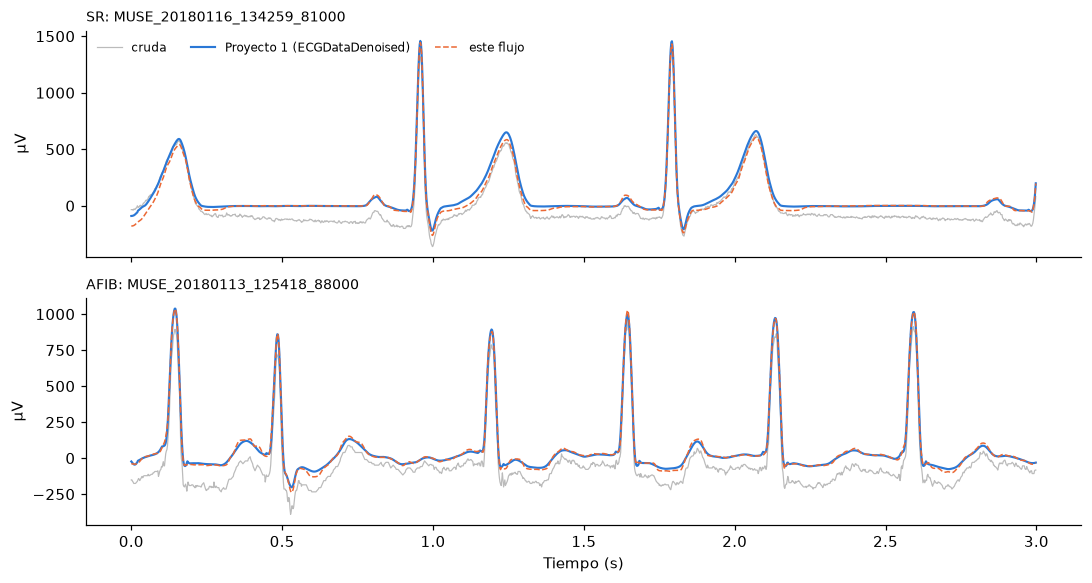

In [121]:
if VALIDACION:
    t0 = time.perf_counter()
    X_fil_val = np.vstack([filtrar(x) for x in X_cru_val])
    print(f"{len(X_fil_val)} registros filtrados en {time.perf_counter()-t0:.1f} s")
    m_fil = metricas(X_den_val, X_fil_val); m_cru = metricas(X_den_val, X_cru_val)
    comp = pd.concat({"cruda vs Proyecto 1": m_cru, "filtrada (este flujo) vs Proyecto 1": m_fil}, axis=1)
    comp["Estado"] = diag["Estado"].values[idx_val]
    display(comp.groupby("Estado").mean().round(3))

    fig, axes = plt.subplots(2, 1, figsize=(10, 5.4), sharex=True)
    for a, g in zip(axes, ["SR", "AFIB"]):
        k = int(np.where(diag["Estado"].values[idx_val] == g)[0][0]); sl = slice(0, 3 * FS)
        a.plot(t[sl], X_cru_val[k][sl], color="#bbb", lw=0.8, label="cruda")
        a.plot(t[sl], X_den_val[k][sl], color="#2a78d6", lw=1.4, label="Proyecto 1 (ECGDataDenoised)")
        a.plot(t[sl], X_fil_val[k][sl], color="#eb6834", lw=1.0, ls="--", label="este flujo")
        a.set_title(f"{g}: {nombres_val[k]}", loc="left", fontsize=9); a.set_ylabel("µV")
    axes[0].legend(frameon=False, ncol=3, fontsize=8); axes[-1].set_xlabel("Tiempo (s)"); plt.tight_layout(); plt.show()

### 3.4 Espectro antes y después

Se estima la densidad espectral de potencia (PSD) promedio de los registros de validación con el método de Welch [8]: la señal se divide en segmentos de 1024 muestras con solapamiento, se calcula el periodograma de cada uno y se promedian, lo que reduce la varianza de la estimación. Se compara la señal cruda, la filtrada con nuestro flujo y la del Proyecto 1, para ver en qué frecuencias actúa el filtrado.

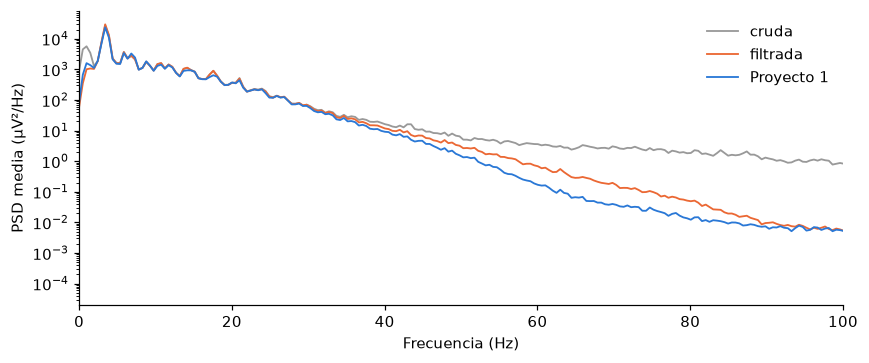

In [122]:
from scipy.signal import welch
def psd(X): 
    f, P = welch(X, fs=FS, nperseg=1024, axis=-1); return f, P.mean(axis=0)
muestra_idx = idx_val if VALIDACION else np.arange(0, len(X_cruda), max(1, len(X_cruda)//25))[:25]
Xc = X_cruda[muestra_idx].astype(float); Xf = np.vstack([filtrar(x) for x in Xc])
fig, ax = plt.subplots(figsize=(8, 3.4))
for X, lab, c in [(Xc, "cruda", "#999"), (Xf, "filtrada", "#eb6834")] + ([(X_den_val, "Proyecto 1", "#2a78d6")] if VALIDACION else []):
    f, P = psd(X); ax.semilogy(f, P, label=lab, color=c, lw=1.2)
ax.set_xlim(0, 100); ax.set_xlabel("Frecuencia (Hz)"); ax.set_ylabel("PSD media (µV²/Hz)"); ax.legend(frameon=False); plt.tight_layout(); plt.show()

### 3.5 Sintonización de `LOESS_FRAC` y `NLM_H`

El artículo no publica la fracción de ventana del LOESS ni el parámetro de suavizado del NLM. Como se tiene la señal filtrada con el flujo original, se prueban 5 × 5 combinaciones y se busca la de menor RMSE medio frente a ella en los registros de validación.

In [123]:
SINTONIZAR = True
if VALIDACION and SINTONIZAR:
    resultados = []
    for frac in [0.05, 0.07, 0.1, 0.15, 0.2]:
        pre = np.vstack([butterworth_pb(x) for x in X_cru_val])
        pre = np.vstack([p - loess_robusto(p, frac=frac) for p in pre])
        for h in [2.0, 3.0, 4.0, 6.0, 8.0]:
            out = np.vstack([nlm_1d(p, h=h) for p in pre])
            resultados.append({"LOESS_FRAC": frac, "NLM_H": h, "RMSE medio (µV)": metricas(X_den_val, out)["RMSE (µV)"].mean()})
    tabla = pd.DataFrame(resultados).sort_values("RMSE medio (µV)")
    display(tabla.head(6).round(3))
    mejor = tabla.iloc[0]
    print(f"Mejor combinación: LOESS_FRAC={mejor['LOESS_FRAC']}, NLM_H={mejor['NLM_H']}  (actuales: {LOESS_FRAC}, {NLM_H})")

,LOESS_FRAC,NLM_H,RMSE medio (µV)
13,0.10,6.0,19.768
12,0.10,4.0,20.056
18,0.15,6.0,20.334
14,0.10,8.0,20.348
11,0.10,3.0,20.724
19,0.15,8.0,20.766


Mejor combinación: LOESS_FRAC=0.1, NLM_H=6.0  (actuales: 0.1, 4.0)


### 3.6 Filtrado de las 2000 señales

Se aplica el flujo completo, con los parámetros elegidos, a las 2000 señales de la muestra. El cálculo se reparte entre los núcleos del procesador (`joblib`) y el resultado se guarda en la caché para no repetirlo.

In [124]:
def _filtrar_lote(lote, frac, h):
    return np.vstack([filtrar(x, frac, h) for x in lote]).astype(np.float32)

if os.path.exists(cache("lead2_filtrada.npy")) and not RECALCULAR:
    X_fil = np.load(cache("lead2_filtrada.npy"))
else:
    t0 = time.perf_counter()
    nj = os.cpu_count() if N_JOBS == -1 else N_JOBS
    lotes = np.array_split(X_cruda, max(nj * 4, 1))
    X_fil = np.vstack(Parallel(n_jobs=N_JOBS)(delayed(_filtrar_lote)(l, LOESS_FRAC, NLM_H) for l in lotes))
    np.save(cache("lead2_filtrada.npy"), X_fil)
    print(f"{len(X_fil)} registros filtrados en {time.perf_counter()-t0:.1f} s")
print("Matriz filtrada:", X_fil.shape, "| NaN:", int(np.isnan(X_fil).sum()))

Matriz filtrada: (2000, 5000) | NaN: 0


## Punto 3. Análisis: filtrado de las señales

**Qué hace cada etapa (registro de prueba, sección 3.2).** El Butterworth elimina el ruido fino de alta frecuencia sin cambiar la forma de las ondas. El LOESS estima la línea de base lenta (curva roja) y, al restarla, la señal queda centrada en cero. El NLM suaviza el ruido residual conservando la altura de los complejos QRS. Con el filtro de orden 3 y la implementación vectorizada, el flujo completo toma entre 30 y 50 ms por registro en este computador (varía según la ejecución); el LOESS y el NLM son las etapas más costosas.

**Validación (sección 3.3).** La señal filtrada con nuestro flujo se parece mucho más a la del Proyecto 1 que la señal cruda:

| Clase | RMSE cruda (µV) | RMSE filtrada (µV) | $\rho$ cruda | $\rho$ filtrada | SNR cruda (dB) | SNR filtrada (dB) |
|---|---|---|---|---|---|---|
| AFIB | 65,7 | 14,0 | 0,905 | 0,991 | 6,8 | 21,1 |
| GSVT | 125,7 | 34,5 | 0,952 | 0,996 | 8,5 | 20,7 |
| SB | 48,8 | 13,5 | 0,954 | 0,997 | 8,7 | 20,3 |
| SR | 100,8 | 18,3 | 0,814 | 0,994 | 3,3 | 19,0 |

El error se reduce entre 3,6 y 5,5 veces, la correlación pasa de 0,81–0,95 a 0,991–0,997 y la SNR sube de 3–9 dB a 19–21 dB. La mayor mejora se da en SR, cuya señal cruda tenía una deriva de línea de base fuerte (correlación de solo 0,814): ese es justamente el tipo de perturbación que corrige el LOESS. El error absoluto más alto queda en GSVT (34,5 µV): a frecuencias de ~160 lpm los complejos están muy próximos, la ventana del LOESS (1 s) contiene varios QRS y pequeñas diferencias de suavizado pesan más. Aun así, su correlación es de 0,996.

**Espectro (sección 3.4).** La señal cruda tiene un exceso de potencia por debajo de ~2 Hz, que corresponde a la deriva de la línea de base y desaparece tras el filtrado. Entre ~2 y ~30 Hz, donde está la mayor parte de la energía del ECG (las armónicas de la frecuencia cardiaca, las ondas P y T y el QRS), las tres curvas coinciden: el filtrado no altera la información útil. Por encima de ~30 Hz, la señal cruda tiene un piso de ruido de banda ancha, unas 100 veces mayor que el de las señales filtradas a 80–100 Hz. No se observa un pico de interferencia de red en 50 o 60 Hz, así que el ruido de alta frecuencia de estos registros es de banda ancha. Entre 40 y 90 Hz nuestra señal conserva algo más de potencia que la del Proyecto 1, lo que indica que el flujo original atenúa un poco más las altas frecuencias, posiblemente por parámetros que el artículo no especifica.

**Sintonización (sección 3.5).** La mejor combinación fue `LOESS_FRAC` = 0,10 y `NLM_H` = 6 (RMSE medio de 19,8 µV), y la segunda, la usada en este trabajo: 0,10 y 4 (20,1 µV). La diferencia es de 0,3 µV (1,4 %), despreciable frente al error de la señal cruda, así que se conservó `NLM_H` = 4. Un $h$ menor suaviza menos y conserva mejor los picos. La fracción de 0,10 fue la mejor con cualquier $h$: ventanas más cortas empiezan a seguir las ondas P y T como si fueran línea de base, y más largas no siguen bien la deriva.

**Limitación de la validación.** La referencia es la señal ya filtrada del Proyecto 1, no una señal limpia "verdadera". Las métricas miden cuánto se parece nuestro flujo al original, no la calidad absoluta del filtrado.

## 4. Características (punto 4)

Todas las características se calculan **sobre la derivación II ya filtrada** (punto 3), una fila por registro. Hay tres familias, con 59 características en total.

**A. Del Proyecto 1** [9] (5 características). Antes de calcularlas, la señal se prepara como en el Proyecto 1: se le resta una tendencia polinómica de grado 3 y se reescala al intervalo [0, 1].
- `fMP`: **frecuencia de máxima potencia** entre 0,3 y 40 Hz, del espectro con ventana de Hann y relleno de ceros ×8: $f_{MP}=\arg\max_{f}\,|X(f)|^2$.
- `sFSB`, `pct_sFSB`, `sFSB_f0`: número de pares de frecuencias con **bicoherencia** significativa, su porcentaje y cuántos involucran a $f_0$. La señal se divide en $N = 10$ segmentos de 1 s con espectros $X_k(f)$:

$$b(f_1,f_2)=\frac{\left|\sum_{k=1}^{N} X_k(f_1)\,X_k(f_2)\,X_k^*(f_1+f_2)\right|}{\sum_{k=1}^{N}\left|X_k(f_1)\,X_k(f_2)\,X_k^*(f_1+f_2)\right|}$$

  Vale 1 si la fase de $f_1+f_2$ está acoplada con la de $f_1$ y $f_2$ en todos los segmentos, y cerca de 0 si es aleatoria. Un par es significativo si $b > \sqrt{9{,}2/2N} = 0{,}678$. Se usa la región $f_1 \ge f_2 > 0$, $f_1 + f_2 \le 20$ Hz.
- `f0`: **frecuencia fundamental**, el número de latidos por segundo a partir de los picos R detectados con un detector tipo Pan–Tompkins [10]: filtro pasabanda de 5–15 Hz, derivada al cuadrado, integración en ventana de 150 ms y umbral.

**B. Siguiendo a Zheng et al.** [2] (39 características). Con los instantes $t_i$ de los picos R se obtienen los intervalos $RR_i = t_{i+1}-t_i$ y sus diferencias $\Delta RR_i = RR_{i+1}-RR_i$:
- **Estadísticos RR**: número, media $\overline{RR}$, varianza, desviación $\sigma_{RR}$, mediana, mínimo, máximo y rango, y la frecuencia cardiaca $fc = 60/\overline{RR}$ (lpm).
- **Variabilidad**:

$$CV=\frac{\sigma_{RR}}{\overline{RR}}\qquad RMSSD=\sqrt{\frac{1}{n-1}\sum_{i}\Delta RR_i^2}\qquad pNN50=100\cdot\frac{\#\{|\Delta RR_i|>50\text{ ms}\}}{n-1}$$

$$SD1=\frac{\sigma_{\Delta RR}}{\sqrt 2}\qquad SD2=\sqrt{2\sigma_{RR}^2-SD1^2}\qquad \text{irregularidad}=\frac{\overline{|\Delta RR|}}{\overline{RR}}$$

  SD1 y SD2 son los ejes de la nube de Poincaré ($RR_{i+1}$ contra $RR_i$): SD1 mide la variación latido a latido y SD2 la de largo plazo.
- **Picos y valles**: se detectan todos los máximos y mínimos locales con prominencia de al menos el 2 % del rango de la señal. Los máximos a menos de 60 ms de un pico R se asignan al **QRS**, y los demás son **picos no-QRS** (ondas P y T, ruido). Para cada subconjunto (QRS, no-QRS y valles) se calculan el número y la media y la varianza de su altura, ancho (ms) y prominencia, más la amplitud media y el coeficiente de variación de los picos R.

**C. Añadidas por la discusión del punto 1 sobre ondas ausentes o deformadas** (15 características):
- `p_presente`: fracción de latidos con una onda P detectable, es decir, un pico no-QRS con prominencia ≥ 5 % de la amplitud del R en la ventana de 200 a 60 ms antes de cada R. En fibrilación auricular la onda P desaparece y este valor baja. `p_prom_rel` y `p_prom_cv` miden su tamaño relativo al R y su variabilidad; `t_presente` y `t_prom_rel`, lo mismo para la onda T (100–400 ms después del R).
- **Plantilla de latido**: se recortan todos los latidos (250 ms antes y 450 ms después de cada R) y se calcula su mediana muestra a muestra, que es la plantilla $\tilde b$. `corr_latido` es la correlación media de cada latido con la plantilla, y `corr_latido_min` la mínima. `resid_rel` es la desviación media del residuo (latido − plantilla) relativa a la de la plantilla, y `resid_pre_qrs_rel` lo mismo solo antes del QRS, donde aparecen las ondas fibrilatorias.
- **Espectrales**: fracción de potencia en las bandas 0,5–4, 4–9, 9–15 y 15–40 Hz, **entropía espectral** normalizada $H=-\sum_f p_f\log p_f/\log N_f$, donde $p_f$ es la potencia normalizada a suma 1 (vale 1 si la energía está repartida en todas las frecuencias y es baja si se concentra en pocas), y **centroide espectral** $\sum_f p_f f$.

In [125]:
# ===================== Funciones del Proyecto 1 (reutilizadas) =====================
GRADO_TENDENCIA = 3
LONG_SEGMENTO = 500
FMAX_BIS = 20.0
FMIN_FMP, FMAX_FMP, RELLENO = 0.3, 40.0, 8

def preprocesar(x, grado=GRADO_TENDENCIA):
    t = np.arange(len(x))
    x_n = x - np.polynomial.Polynomial.fit(t, x, deg=grado)(t)         # fórmula (1)
    return (x_n - x_n.min()) / (x_n.max() - x_n.min())                # fórmula (2)

def frecuencia_max_potencia(x, fs=FS):
    x = x - x.mean(); nfft = RELLENO * len(x)
    P = np.abs(np.fft.rfft(x * np.hanning(len(x)), n=nfft)) ** 2
    f = np.fft.rfftfreq(nfft, d=1 / fs)
    v = (f >= FMIN_FMP) & (f <= FMAX_FMP)
    return f[v][np.argmax(P[v])]

# índices fijos de la región triangular de la bicoherencia (se calculan una sola vez)
_K = int(round(FMAX_BIS * LONG_SEGMENTO / FS)) + 1
_I = np.arange(_K); _IDX_SUMA = _I[:, None] + _I[None, :]
_F = np.fft.rfftfreq(LONG_SEGMENTO, d=1 / FS)[:_K]
_F1, _F2 = np.meshgrid(_F, _F, indexing="ij")
_REGION = (_F2 > 0) & (_F1 >= _F2) & (_F1 + _F2 <= FMAX_BIS)

def bicoherencia(x):
    N = len(x) // LONG_SEGMENTO
    X = np.fft.rfft(x[:N * LONG_SEGMENTO].reshape(N, LONG_SEGMENTO), axis=1)
    prod = X[:, :_K, None] * X[:, None, :_K] * np.conj(X[:, _IDX_SUMA])      # fórmula (3)
    B = np.abs(prod.sum(axis=0)) / np.abs(prod).sum(axis=0)                 # fórmula (4)
    return B, N

B_QRS, A_QRS = butter(2, [5, 15], btype="bandpass", fs=FS)
def detectar_picos_r(x, fs=FS, umbral=0.3, distancia_min=0.24, percentil=99.5):
    y = filtfilt(B_QRS, A_QRS, x - np.mean(x))
    energia = np.gradient(y) ** 2
    ventana = int(0.15 * fs)
    energia = np.convolve(energia, np.ones(ventana) / ventana, mode="same")
    picos, _ = find_peaks(energia, distance=int(distancia_min * fs), height=umbral * np.percentile(energia, percentil))
    desv = np.abs(x - np.median(x)); r = int(0.1 * fs)
    picos = np.array([max(p - r, 0) + np.argmax(desv[max(p - r, 0):p + r + 1]) for p in picos], dtype=int)
    return np.unique(picos)

def detectar_r_robusto(x, fs=FS):
    # Detector del Proyecto 1; si encuentra < 3 latidos (artefactos grandes inflan el umbral) se repite con un umbral menos sensible a picos aislados.
    r = detectar_picos_r(x, fs)
    return r if len(r) >= 3 else detectar_picos_r(x, fs, percentil=95)

In [126]:
# Verificación del detector de picos R en señales de validación
reintentos = 0
registros_revisados = 0

for x in X_fil_val:
    r_inicial = detectar_picos_r(x, fs=FS)

    registros_revisados += 1
    if len(r_inicial) < 3:
        reintentos += 1

print(f"Registros revisados: {registros_revisados}")
print(f"Registros con menos de 3 picos en la primera detección: {reintentos}")

Registros revisados: 20
Registros con menos de 3 picos en la primera detección: 0


In [127]:
# ===================== Características nuevas =====================
def _stats(v):
    return (float(np.mean(v)), float(np.var(v))) if len(v) else (0.0, 0.0)

def _presencia(x, r, pic_idx, pic_prom, ini, fin, umbral, fs=FS):
    # Por latido: prominencia máxima de un extremo no-QRS dentro de [r+ini, r+fin] (segundos).
    proms = []
    for ri in r:
        a, b = ri + int(ini * fs), ri + int(fin * fs)
        if a < 0 or b >= len(x): continue
        m = (pic_idx >= a) & (pic_idx <= b)
        proms.append(pic_prom[m].max() if m.any() else 0.0)
    proms = np.array(proms)
    if len(proms) == 0: return np.nan, np.nan, np.nan
    return float((proms >= umbral).mean()), float(proms.mean()), float(proms.std() / (proms.mean() + 1e-9))

def extraer_caracteristicas(x, fs=FS):
    x = np.asarray(x, dtype=np.float64); n = len(x); f = {}
    # ---------- A. Proyecto 1 ----------
    s = preprocesar(x)
    f["fMP"] = frecuencia_max_potencia(s)
    B, N = bicoherencia(s); u = np.sqrt(9.2 / (2 * N))
    signif = _REGION & (B > u)
    r_s = detectar_r_robusto(s)
    f0 = (len(r_s) - 1) / ((r_s[-1] - r_s[0]) / fs) if len(r_s) >= 2 else np.nan
    f["sFSB"] = int(signif.sum()); f["pct_sFSB"] = 100 * signif.sum() / _REGION.sum()
    if np.isnan(f0): f["sFSB_f0"] = np.nan
    else:
        k0 = np.argmin(np.abs(_F - f0)); con_f0 = np.zeros_like(_REGION); con_f0[k0, :] = True; con_f0[:, k0] = True
        f["sFSB_f0"] = int((signif & con_f0).sum())
    f["f0"] = f0
    # ---------- B. Zheng: RR, QRS, picos y valles ----------
    r = detectar_r_robusto(x); f["n_qrs"] = len(r)
    rr = np.diff(r) / fs
    if len(rr) >= 2:
        d = np.diff(rr)
        f.update(rr_n=len(rr), rr_media=rr.mean(), rr_var=rr.var(), rr_std=rr.std(), rr_cv=rr.std() / rr.mean(),
                 rr_mediana=np.median(rr), rr_min=rr.min(), rr_max=rr.max(), rr_rango=np.ptp(rr),
                 rmssd=np.sqrt(np.mean(d ** 2)), pnn50=100 * np.mean(np.abs(d) > 0.05),
                 sd1=d.std() / np.sqrt(2), sd2=np.sqrt(max(2 * rr.std() ** 2 - d.std() ** 2 / 2, 0)),
                 irregularidad=np.mean(np.abs(d)) / rr.mean(), fc_lpm=60 / rr.mean())
    else:
        for k in ["rr_n", "rr_media", "rr_var", "rr_std", "rr_cv", "rr_mediana", "rr_min", "rr_max", "rr_rango",
                  "rmssd", "pnn50", "sd1", "sd2", "irregularidad", "fc_lpm"]: f[k] = np.nan
    rango = np.percentile(x, 99) - np.percentile(x, 1)
    xm = x - np.median(x)
    pk, pp = find_peaks(xm, prominence=0.02 * rango, width=0)
    vl, pv = find_peaks(-xm, prominence=0.02 * rango, width=0)
    cerca = np.zeros(len(pk), bool)
    if len(r) and len(pk):
        cerca = np.abs(pk[:, None] - r[None, :]).min(axis=1) <= int(0.06 * fs)
    subconj = {"qrs": (pk[cerca], pp["prominences"][cerca], xm[pk][cerca], pp["widths"][cerca]),
               "nqrs": (pk[~cerca], pp["prominences"][~cerca], xm[pk][~cerca], pp["widths"][~cerca]),
               "valle": (vl, pv["prominences"], -xm[vl], pv["widths"])}
    for nombre, (idx, prom, alt, anc) in subconj.items():
        f[f"n_pk_{nombre}"] = len(idx)
        f[f"{nombre}_alt_m"], f[f"{nombre}_alt_v"] = _stats(alt)
        f[f"{nombre}_anc_m"], f[f"{nombre}_anc_v"] = _stats(anc / fs * 1000)      # ancho en ms
        f[f"{nombre}_prom_m"], f[f"{nombre}_prom_v"] = _stats(prom)
    amp_r = np.abs(xm[r]) if len(r) else np.array([np.nan])
    f["r_amp_media"] = float(np.nanmean(amp_r)); f["r_amp_cv"] = float(np.nanstd(amp_r) / (np.nanmean(amp_r) + 1e-9))
    # ---------- C. Ondas ausentes / morfología ----------
    nq_idx, nq_prom = subconj["nqrs"][0], subconj["nqrs"][1]
    umbral_p = 0.05 * f["r_amp_media"]
    p_pres, p_prom, p_cv = _presencia(x, r, nq_idx, nq_prom, -0.20, -0.06, umbral_p, fs)
    t_pres, t_prom, _ = _presencia(x, r, nq_idx, nq_prom, 0.10, 0.40, umbral_p, fs)
    f.update(p_presente=p_pres, p_prom_rel=p_prom / (f["r_amp_media"] + 1e-9), p_prom_cv=p_cv,
             t_presente=t_pres, t_prom_rel=t_prom / (f["r_amp_media"] + 1e-9))
    pre, post = int(0.25 * fs), int(0.45 * fs)
    ok = r[(r - pre >= 0) & (r + post < n)]
    if len(ok) >= 3:
        M = np.stack([x[i - pre:i + post] for i in ok]); plantilla = np.median(M, axis=0); res = M - plantilla
        Mc = M - M.mean(axis=1, keepdims=True); Pc = plantilla - plantilla.mean()
        corr = (Mc @ Pc) / (np.linalg.norm(Mc, axis=1) * np.linalg.norm(Pc) + 1e-9)
        f["corr_latido"], f["corr_latido_min"] = float(corr.mean()), float(corr.min())
        f["resid_rel"] = float(res.std(axis=1).mean() / (plantilla.std() + 1e-9))
        f["resid_pre_qrs_rel"] = float(res[:, : pre - int(0.06 * fs)].std(axis=1).mean() / (f["r_amp_media"] + 1e-9))
    else:
        f["corr_latido"] = f["corr_latido_min"] = f["resid_rel"] = f["resid_pre_qrs_rel"] = np.nan
    P = np.abs(np.fft.rfft((x - x.mean()) * np.hanning(n))) ** 2; fr = np.fft.rfftfreq(n, 1 / fs)
    tot = P[(fr >= 0.5) & (fr <= 40)].sum() + 1e-12
    for a, b in [(0.5, 4), (4, 9), (9, 15), (15, 40)]:
        f[f"pot_{a}_{b}".replace(".", "p")] = P[(fr >= a) & (fr < b)].sum() / tot
    pn = P[(fr >= 0.5) & (fr <= 40)] / tot; fb = fr[(fr >= 0.5) & (fr <= 40)]
    f["entropia_espectral"] = float(-(pn * np.log(pn + 1e-12)).sum() / np.log(len(pn)))
    f["centroide_espectral"] = float((pn * fb).sum())
    return f

def _caracteristicas_lote(lote):
    out = []
    for x in lote:
        try: out.append(extraer_caracteristicas(x))
        except Exception as e: out.append({"_error": str(e)})
    return out

### 4.1 Construcción del dataframe de trabajo

In [128]:
RUTA_CARAC = cache("caracteristicas.csv")
if os.path.exists(RUTA_CARAC) and not RECALCULAR:
    df = pd.read_csv(RUTA_CARAC)
else:
    t0 = time.perf_counter()
    nj = os.cpu_count() if N_JOBS == -1 else N_JOBS
    lotes = np.array_split(X_fil, max(nj * 4, 1))
    filas = [f for lote in Parallel(n_jobs=N_JOBS)(delayed(_caracteristicas_lote)(l) for l in lotes) for f in lote]
    carac = pd.DataFrame(filas)
    df = pd.concat([diag[["FileName"]].rename(columns={"FileName": "Registro"}).reset_index(drop=True), carac], axis=1)
    df.to_csv(RUTA_CARAC, index=False)
    print(f"{len(df)} registros en {time.perf_counter()-t0:.1f} s")

# Estado y Clase se recalculan siempre desde el diagnóstico (así N_CLASES se puede cambiar sin recalcular nada)
df = df.drop(columns=["Estado", "Clase"], errors="ignore")
_lab = diag.set_index("FileName")[["Estado", "Clase"]]
df = df.join(_lab, on="Registro")
if "_error" in df.columns: print("Registros con error:", int(df["_error"].notna().sum()))
# Atributos opcionales
extra = diag.set_index("FileName")
if USAR_EDAD_SEXO:
    df["Edad"] = extra.loc[df["Registro"], "PatientAge"].values
    df["Sexo"] = (extra.loc[df["Registro"], "Gender"].values == "MALE").astype(int)
if USAR_ATRIB_MUSE:
    for c in ["VentricularRate", "AtrialRate", "QRSDuration", "QTInterval", "QTCorrected", "RAxis", "TAxis", "QOnset", "QOffset", "TOffset"]:
        df[c] = extra.loc[df["Registro"], c].values

NO_CARAC = {"Registro", "Estado", "Clase", "_error"}
CARACTERISTICAS = [c for c in df.columns if c not in NO_CARAC]
print(f"\n{len(CARACTERISTICAS)} características | valores faltantes: {int(df[CARACTERISTICAS].isna().sum().sum())}")
df[["Registro", "Estado", "Clase"] + CARACTERISTICAS].head()


59 características | valores faltantes: 4


,Registro,Estado,Clase,fMP,sFSB,pct_sFSB,sFSB_f0,f0,n_qrs,rr_n,...,corr_latido,corr_latido_min,resid_rel,resid_pre_qrs_rel,pot_0p5_4,pot_4_9,pot_9_15,pot_15_40,entropia_espectral,centroide_espectral
0,MUSE_20180111_160355_88000,SB,SB,2.4875,79,79.0,4,0.838926,9,8,...,0.992141,0.975703,0.123128,0.017151,0.204171,0.167444,0.231189,0.396331,0.872877,13.247847
1,MUSE_20180111_160635_98000,SB,SB,7.3375,99,99.0,19,0.952835,9,8,...,0.996418,0.993553,0.083477,0.009566,0.185725,0.291400,0.222701,0.300068,0.864715,11.719088
2,MUSE_20180111_160647_22000,SB,SB,1.5625,71,71.0,13,0.915332,9,8,...,0.945477,0.652708,0.693435,0.030297,0.231199,0.393963,0.219527,0.155302,0.829130,8.556580
3,MUSE_20180111_160729_69000,SB,SB,1.9500,100,100.0,19,0.977836,10,9,...,0.956677,0.838168,0.277340,0.054786,0.430386,0.231731,0.163256,0.174612,0.696127,8.282295
4,MUSE_20180111_163357_09000,SB,SB,3.7500,98,98.0,18,0.750375,7,6,...,0.997869,0.995237,0.061627,0.005428,0.388074,0.361335,0.164580,0.085777,0.729966,7.008493


### 4.2 Justificación de la selección

La tabla resume por qué se espera que cada grupo de características ayude a discriminar los ritmos, y la siguiente muestra la mediana de algunas características clave por clase, para comprobarlo con los datos.

In [129]:
JUSTIFICACION = pd.DataFrame([
    ("fMP, f0, fc_lpm", "Proyecto 1 / RR", "Separan ritmos lentos (SB), normales (SR) y rápidos (GSVT); en ritmo regular la fMP es armónica de la frecuencia cardíaca"),
    ("sFSB, sFSB_f0, pct_sFSB", "Proyecto 1", "El acoplamiento de fase entre armónicas se pierde cuando el ritmo es irregular (FA)"),
    ("rr_media, rr_var, rr_std, rr_cv, rr_min/max/rango, rmssd, pnn50, sd1, sd2, irregularidad, rr_n, n_qrs", "Zheng 2020", "Resumen de la regularidad de los intervalos RR: la FA es 'irregularmente irregular'"),
    ("*_alt, *_anc, *_prom (qrs / nqrs / valle)", "Zheng 2020", "Forma de los complejos y de las ondas no-QRS: altura, ancho y prominencia; se calculan solo en la derivación II"),
    ("p_presente, p_prom_rel, p_prom_cv", "Punto 1 (ondas ausentes)", "Mide directamente si existe onda P antes de cada QRS: desaparece en FA"),
    ("t_presente, t_prom_rel", "Punto 1", "Presencia y tamaño de la onda T"),
    ("corr_latido(_min), resid_rel, resid_pre_qrs_rel", "Punto 1", "Parecido de cada latido a la plantilla y actividad previa al QRS (ondas f de la FA, P ausente o variable)"),
    ("pot_* , entropia_espectral, centroide_espectral", "Espectrales", "Reparto de la energía en frecuencia: en GSVT se concentra en pocas armónicas (entropía baja) y en FA se dispersa (entropía alta)"),
], columns=["Características", "Origen", "Por qué ayudan a discriminar"])
pd.set_option("display.max_colwidth", 140); display(JUSTIFICACION)

,Características,Origen,Por qué ayudan a discriminar
0,"fMP, f0, fc_lpm",Proyecto 1 / RR,"Separan ritmos lentos (SB), normales (SR) y rápidos (GSVT); en ritmo regular la fMP es armónica de la frecuencia cardíaca"
1,"sFSB, sFSB_f0, pct_sFSB",Proyecto 1,El acoplamiento de fase entre armónicas se pierde cuando el ritmo es irregular (FA)
2,"rr_media, rr_var, rr_std, rr_cv, rr_min/max/rango, rmssd, pnn50, sd1, sd2, irregularidad, rr_n, n_qrs",Zheng 2020,Resumen de la regularidad de los intervalos RR: la FA es 'irregularmente irregular'
3,"*_alt, *_anc, *_prom (qrs / nqrs / valle)",Zheng 2020,"Forma de los complejos y de las ondas no-QRS: altura, ancho y prominencia; se calculan solo en la derivación II"
4,"p_presente, p_prom_rel, p_prom_cv",Punto 1 (ondas ausentes),Mide directamente si existe onda P antes de cada QRS: desaparece en FA
5,"t_presente, t_prom_rel",Punto 1,Presencia y tamaño de la onda T
6,"corr_latido(_min), resid_rel, resid_pre_qrs_rel",Punto 1,"Parecido de cada latido a la plantilla y actividad previa al QRS (ondas f de la FA, P ausente o variable)"
7,"pot_* , entropia_espectral, centroide_espectral",Espectrales,Reparto de la energía en frecuencia: en GSVT se concentra en pocas armónicas (entropía baja) y en FA se dispersa (entropía alta)


In [130]:
claves = ["fc_lpm", "rr_cv", "p_presente", "corr_latido", "sFSB", "fMP", "entropia_espectral"]
claves = [c for c in claves if c in df.columns]
display(df.groupby("Estado")[claves].median().round(3).loc[[g for g in ORDEN_5 if g in df["Estado"].unique()]])

,fc_lpm,rr_cv,p_presente,corr_latido,sFSB,fMP,entropia_espectral
Estado,,,,,,,
SB,55.743,0.020,1.000,0.996,98.0,3.325,0.788
SR,73.407,0.021,1.000,0.995,84.0,4.000,0.769
AFIB,92.573,0.189,0.333,0.945,75.0,3.475,0.826
GSVT,162.595,0.009,0.592,0.982,59.0,4.663,0.537


### 4.3 Redundancia entre características

Se calcula la correlación de Pearson entre todos los pares de características y se listan los pares con $|r| \ge 0{,}90$. Dos características muy correlacionadas llevan casi la misma información.

In [131]:

# Análisis de redundancia mediante correlación de Pearson

corr_carac = df[CARACTERISTICAS].corr(method="pearson")

# Obtener únicamente parejas únicas de características
pares_corr = (
    corr_carac.where(np.triu(np.ones(corr_carac.shape), k=1).astype(bool))
    .stack()
    .reset_index()
)

pares_corr.columns = ["Característica 1", "Característica 2", "Correlación"]

# Ordenar por magnitud de correlación
pares_corr["|r|"] = pares_corr["Correlación"].abs()
pares_corr = pares_corr.sort_values("|r|", ascending=False)

# Mostrar parejas con correlación elevada
display(
    pares_corr.loc[pares_corr["|r|"] >= 0.90]
    [["Característica 1", "Característica 2", "Correlación"]]
    .round(3)
)

print(
    "Número de parejas con |r| >= 0.90:",
    int((pares_corr["|r|"] >= 0.90).sum())
)


,Característica 1,Característica 2,Correlación
280,n_qrs,rr_n,1.000
58,sFSB,pct_sFSB,1.000
241,f0,fc_lpm,1.000
294,n_qrs,fc_lpm,0.998
346,rr_n,fc_lpm,0.998
227,f0,rr_n,0.998
226,f0,n_qrs,0.998
388,rr_media,rr_mediana,0.987
491,rr_std,rmssd,0.983
490,rr_std,rr_rango,0.971


Número de parejas con |r| >= 0.90: 28


### 4.4 Prueba de Kruskal-Wallis

Para comprobar estadísticamente si cada característica difiere entre las cuatro clases se usa la prueba de **Kruskal-Wallis** [11], la versión no paramétrica del ANOVA: no supone distribución normal, que muchas de estas características no tienen. Se ordenan todos los $N$ valores de menor a mayor, y $\bar R_g$ es el rango promedio de la clase $g$, que tiene $n_g$ registros:

$$H=\frac{12}{N(N+1)}\sum_{g=1}^{4} n_g\,\bar R_g^{\,2}-3(N+1)$$

Si las cuatro clases tienen la misma distribución, $H$ sigue aproximadamente una $\chi^2$ con 3 grados de libertad. Como se hacen 59 pruebas, los valores $p$ se corrigen con el método de **Benjamini-Hochberg** [12], que controla la proporción de falsos descubrimientos.

Con $N = 2000$ registros, casi cualquier diferencia resulta significativa, así que además se calcula el **tamaño del efecto** [13]:

$$\varepsilon^2=\frac{H}{N-1}$$

Varía entre 0 y 1, y se interpreta como pequeño desde 0,01, mediano desde 0,08 y grande desde 0,26.

In [132]:
from scipy.stats import kruskal
from statsmodels.stats.multitest import multipletests

# Kruskal-Wallis: ¿la característica difiere entre las cuatro clases?
grupos = ["SB", "SR", "AFIB", "GSVT"]
resultados_kw = []
for caracteristica in CARACTERISTICAS:
    muestras = [df.loc[df["Estado"] == grupo, caracteristica].dropna() for grupo in grupos]
    if all(len(m) > 0 for m in muestras):              # los cuatro grupos deben tener datos
        H, p = kruskal(*muestras)
        n = sum(len(m) for m in muestras)
        resultados_kw.append({"Característica": caracteristica, "H": H, "p": p,
                              "epsilon2": H / (n - 1)})  # tamaño del efecto
tabla_kw = pd.DataFrame(resultados_kw)

# Corrección por múltiples comparaciones (Benjamini-Hochberg)
tabla_kw["p_ajustada"] = multipletests(tabla_kw["p"], method="fdr_bh")[1]
tabla_kw["Efecto"] = pd.cut(tabla_kw["epsilon2"], [0, 0.01, 0.08, 0.26, 1],
                            labels=["despreciable", "pequeño", "mediano", "grande"], right=False)
tabla_kw = tabla_kw.sort_values("epsilon2", ascending=False).reset_index(drop=True)
display(tabla_kw.round(4))

print(f"Características evaluadas: {len(tabla_kw)} | significativas (p ajustada < 0,05): {(tabla_kw['p_ajustada'] < 0.05).sum()}")
print("Tamaño del efecto:", tabla_kw["Efecto"].value_counts().to_dict())


,Característica,H,p,epsilon2,p_ajustada,Efecto
0,rr_mediana,1530.6772,0.0,0.7657,0.0,grande
1,rr_min,1509.8582,0.0,0.7553,0.0,grande
2,rr_media,1500.3070,0.0,0.7505,0.0,grande
3,fc_lpm,1500.2997,0.0,0.7505,0.0,grande
4,f0,1500.2484,0.0,0.7505,0.0,grande
5,n_qrs,1486.9167,0.0,0.7438,0.0,grande
6,rr_n,1486.9167,0.0,0.7438,0.0,grande
7,rr_max,1168.2233,0.0,0.5844,0.0,grande
8,valle_anc_v,1037.2034,0.0,0.5189,0.0,grande
9,n_pk_qrs,968.4661,0.0,0.4845,0.0,grande


Características evaluadas: 59 | significativas (p ajustada < 0,05): 59
Tamaño del efecto: {'grande': 29, 'pequeño': 15, 'mediano': 15, 'despreciable': 0}


## Punto 4. Análisis: características

**Dataframe de trabajo.** Se construyó una tabla de 2000 filas (una por registro, 500 por clase) con el nombre del registro, su clase y las 59 características: 5 de la familia A, 39 de la B y 15 de la C. Solo hubo 4 valores faltantes, todos en un mismo registro de AFIB en el que no fue posible recortar tres latidos completos para la plantilla (`corr_latido`, `corr_latido_min`, `resid_rel` y `resid_pre_qrs_rel`). Se imputan con la mediana del entrenamiento antes de clasificar.

**Diferencias entre clases (mediana por clase):**

| Característica | SB | SR | AFIB | GSVT |
|---|---|---|---|---|
| Frecuencia cardiaca (lpm) | 55,7 | 73,4 | 92,6 | 162,6 |
| Coeficiente de variación RR | 0,020 | 0,021 | **0,189** | 0,009 |
| Fracción de latidos con onda P | 1,00 | 1,00 | **0,33** | 0,59 |
| Correlación latido–plantilla | 0,996 | 0,995 | **0,945** | 0,982 |
| Residuo entre latidos (relativo) | 0,09 | 0,10 | **0,31** | 0,17 |
| sFSB (pares con bicoherencia significativa) | 98 | 84 | 75 | 59 |
| Entropía espectral | 0,79 | 0,77 | 0,83 | **0,54** |

1. **La frecuencia ordena las clases** (SB < SR < AFIB < GSVT). SB y SR solo se separan por el umbral clínico de 60 lpm, y por lo demás son iguales en forma y regularidad.
2. **La irregularidad aísla la fibrilación auricular.** El coeficiente de variación de RR es unas 9 veces mayor en AFIB que en SR (0,189 frente a 0,021), y GSVT es la más regular (0,009). Es el ritmo "irregularmente irregular" típico de la fibrilación.
3. **Las características de ondas ausentes confirman el mecanismo.** En AFIB solo un tercio de los latidos tiene onda P detectable, frente a todos en SB y SR. Además, los latidos se parecen menos entre sí (0,945) y queda más actividad entre ellos (residuo de 0,31, tres veces el de SR), coherente con las ondas fibrilatorias.
4. **Limitación de `p_presente`.** En GSVT también baja (0,59), probablemente no porque falte la onda P, sino porque a ~160 lpm se superpone con la onda T del latido anterior y cae fuera de la ventana de búsqueda. Esta característica debe interpretarse junto con la frecuencia.
5. **Las características del Proyecto 1 siguen a la frecuencia.** sFSB decrece al aumentar la frecuencia (98, 84, 75, 59): al subir $f_0$, caben menos armónicas por debajo de 20 Hz. No separa específicamente a AFIB. La entropía espectral sí distingue a GSVT (0,54), porque a frecuencias altas la energía se concentra en pocas armónicas muy espaciadas.

**Kruskal-Wallis y tamaño del efecto.** Las 59 características difieren significativamente entre clases ($p$ ajustado < 0,05), pero el tamaño del efecto varía mucho: 29 tienen efecto grande ($\varepsilon^2 \ge 0{,}26$), 15 mediano y 15 pequeño. Los efectos más grandes son todos de ritmo: mediana de RR ($\varepsilon^2 = 0{,}77$), RR mínimo y medio, frecuencia cardiaca y $f_0$ (0,75), y número de QRS (0,74). Las de menor efecto son medidas de forma o de potencia en bandas (por ejemplo, varianza de la altura del QRS, 0,011, o potencia en 4–9 Hz, 0,038). Este orden coincide con la importancia que después les asigna XGBoost (punto 7).

**Redundancia.** 28 pares de características tienen $|r| \ge 0{,}90$, y tres son **idénticos** ($r = 1{,}000$): `f0` y `fc_lpm` ($fc = 60\,f_0$), `n_qrs` y `rr_n` ($n_{RR} = n_{QRS}-1$) y `sFSB` y `pct_sFSB` (uno es el porcentaje del otro). La redundancia no afecta a los árboles ni a la SVM, y con estandarización y regularización tampoco a las redes, pero reparte la importancia entre características equivalentes. Se conservaron todas para mantener la comparación con el Proyecto 1 y con Zheng et al.

## Clasificación

### Protocolo común a todos los modelos

Para que los modelos sean comparables entre sí y la evaluación sea honesta, todos siguen el mismo procedimiento:

1. **Partición estratificada 80/20.** Los 2000 registros se dividen una sola vez en entrenamiento (1600) y prueba (400), con la misma proporción de cada clase en ambos conjuntos (400 y 100 por clase), como en Zheng et al. [2]. Todos los modelos usan exactamente la misma partición (`random_state = 42`).
2. **Sin fuga de información.** Los valores faltantes se imputan con la **mediana del entrenamiento**, y las características se estandarizan con la media y la desviación estándar **del entrenamiento**:

$$z = \frac{x-\mu_{train}}{\sigma_{train}}$$

   Si se calcularan con todos los datos, la información del conjunto de prueba se filtraría al modelo, y las métricas saldrían mejores de lo que serían con pacientes nuevos. La estandarización es necesaria para las redes, la SVM y K-means, que dependen de distancias o de combinaciones de las características. Sin ella, una característica en milisegundos dominaría sobre una entre 0 y 1.
3. **El conjunto de prueba solo se usa al final**, para medir. Cualquier ajuste (parada temprana, búsqueda de hiperparámetros) se hace con una parte del entrenamiento.
4. **Clases balanceadas.** La muestra tiene 500 registros por clase, así que no hace falta compensar el desbalance.

### Métricas de evaluación

Para cada clase $k$ se cuentan, en el conjunto de prueba, los verdaderos positivos ($TP_k$: registros de la clase $k$ predichos como $k$), los falsos positivos ($FP_k$: predichos como $k$ sin serlo) y los falsos negativos ($FN_k$: de la clase $k$ predichos como otra clase). Con $N$ registros y $K$ clases:

**Exactitud**: fracción de registros bien clasificados (la diagonal de la matriz de confusión entre el total).

$$\text{Exactitud}=\frac{1}{N}\sum_{k=1}^{K} TP_k$$

**Precisión**: de los registros que el modelo asignó a la clase $k$, ¿cuántos eran realmente de esa clase?

$$\text{Precisión}_k=\frac{TP_k}{TP_k+FP_k}$$

**Sensibilidad (recall)**: de los registros reales de la clase $k$, ¿cuántos encontró el modelo?

$$\text{Sensibilidad}_k=\frac{TP_k}{TP_k+FN_k}$$

**F1**: media armónica de precisión y sensibilidad. Solo es alta si las dos lo son.

$$F1_k=2\cdot\frac{\text{Precisión}_k\cdot\text{Sensibilidad}_k}{\text{Precisión}_k+\text{Sensibilidad}_k}$$

**F1 macro**: promedio simple del F1 de todas las clases. Cada clase pesa lo mismo, así que un modelo no puede obtener un buen F1 macro clasificando bien solo las clases fáciles.

$$F1_{macro}=\frac{1}{K}\sum_{k=1}^{K}F1_k$$

**Matriz de confusión**: tabla de $K\times K$ donde la fila es la clase real y la columna la predicha. La diagonal son los aciertos, y cada celda fuera de la diagonal muestra qué clase se confundió con cuál.

**Error de muestreo.** Como la prueba tiene un número finito de registros, la exactitud medida tiene incertidumbre. Su error estándar es aproximadamente

$$EE=\sqrt{\frac{p\,(1-p)}{n}}$$

Por ejemplo, con $p=0{,}88$ y $n=400$, $EE\approx 0{,}016$ (±1,6 puntos). Diferencias entre modelos menores que esto no permiten afirmar que uno sea mejor que otro.

In [133]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score, f1_score,
                             silhouette_score, adjusted_rand_score, normalized_mutual_info_score, roc_auc_score)
from xgboost import XGBClassifier

df_m = df.dropna(subset=["Clase"]).reset_index(drop=True)
X_all = df_m[CARACTERISTICAS].astype(float).values
le = LabelEncoder().fit(CLASES); y_all = le.transform(df_m["Clase"])

idx_tr, idx_te = train_test_split(np.arange(len(df_m)), test_size=0.20, stratify=y_all, random_state=SEMILLA)
imp = SimpleImputer(strategy="median").fit(X_all[idx_tr])
sc  = StandardScaler().fit(imp.transform(X_all[idx_tr]))
prep = lambda X: sc.transform(imp.transform(X))
Xtr, Xte, ytr, yte = prep(X_all[idx_tr]), prep(X_all[idx_te]), y_all[idx_tr], y_all[idx_te]

def sobremuestrear(X, y, seed=SEMILLA):
    rng = np.random.default_rng(seed); n_max = np.bincount(y).max(); ix = []
    for c in np.unique(y):
        i = np.where(y == c)[0]; ix.append(np.r_[i, rng.choice(i, n_max - len(i), replace=True)])
    ix = rng.permutation(np.concatenate(ix)); return X[ix], y[ix]

print(f"Entrenamiento: {Xtr.shape} | Prueba: {Xte.shape} | Clases: {[str(c) for c in le.classes_]}")
print("Distribución en entrenamiento:", {str(c): int(n) for c, n in zip(le.classes_, np.bincount(ytr))})

def evaluar(nombre, y_real, y_pred, clases):
    return {"modelo": nombre, "exactitud": accuracy_score(y_real, y_pred),
            "F1 macro": f1_score(y_real, y_pred, average="macro"), "F1 ponderado": f1_score(y_real, y_pred, average="weighted")}

def graficar_matrices(resultados, clases, y_real, titulo):
    k = len(resultados); fig, axes = plt.subplots(1, k, figsize=(4.6 * k, 4.2))
    axes = np.atleast_1d(axes)
    for ax, (nombre, pred) in zip(axes, resultados.items()):
        ConfusionMatrixDisplay(confusion_matrix(y_real, pred, labels=np.arange(len(clases))), display_labels=clases).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
        ax.set_title(f"{nombre}\nF1 macro = {f1_score(y_real, pred, average='macro'):.3f}", fontsize=9)
    fig.suptitle(titulo, y=1.02); plt.tight_layout(); plt.show()

Entrenamiento: (1600, 59) | Prueba: (400, 59) | Clases: ['AFIB', 'GSVT', 'SB', 'SR']
Distribución en entrenamiento: {'AFIB': 400, 'GSVT': 400, 'SB': 400, 'SR': 400}


### 5. Redes neuronales — 4 clases

**¿Qué es un perceptrón multicapa (MLP)?** Es una red de neuronas organizadas en capas; se usa la implementación `MLPClassifier` de scikit-learn [14]. Cada neurona recibe las salidas de la capa anterior, las combina con unos pesos, les suma un sesgo y aplica una función de activación:

$$h^{(l)} = \text{ReLU}\left(W^{(l)}\,h^{(l-1)} + b^{(l)}\right), \qquad \text{ReLU}(z)=\max(0,z)$$

La capa de entrada son las 59 características estandarizadas, $h^{(0)}=x$. ReLU deja pasar los valores positivos y anula los negativos; eso permite que la red aprenda fronteras no lineales entre clases. La capa de salida usa **softmax**, que convierte las salidas en probabilidades que suman 1:

$$\hat p_k = \frac{e^{z_k}}{\sum_{j=1}^{K} e^{z_j}}, \qquad k = 1,\dots,K$$

La red predice la clase con mayor $\hat p_k$. Para aprender los pesos se minimiza la **entropía cruzada** con regularización L2 ($\alpha = 10^{-3}$), que castiga los pesos grandes para reducir el sobreajuste:

$$L = -\frac{1}{N}\sum_{i=1}^{N}\sum_{k=1}^{K} y_{ik}\,\log \hat p_{ik} \;+\; \frac{\alpha}{2}\,\lVert W\rVert^2$$

Los pesos se actualizan con el optimizador **Adam** [15], que ajusta el tamaño del paso de cada peso según el promedio de sus gradientes ($m_t$) y de sus gradientes al cuadrado ($v_t$):

$$m_t=\beta_1 m_{t-1}+(1-\beta_1)\,g_t,\qquad v_t=\beta_2 v_{t-1}+(1-\beta_2)\,g_t^2,\qquad \theta_t=\theta_{t-1}-\eta\,\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}$$

con $\eta = 10^{-3}$, $\beta_1=0{,}9$ y $\beta_2=0{,}999$. Además se usa **parada temprana**: se reserva el 15 % del entrenamiento como validación interna y se detiene el entrenamiento si la exactitud de validación no mejora en 20 épocas seguidas.

**Diseño de las arquitecturas con las reglas heurísticas.** Con $n_{in} = 59$ entradas y $n_{out} = 4$ salidas:

| Regla | Condición | Valor para este problema |
|---|---|---|
| 1 | $n_{out} \le n_{ocultas} \le n_{in}$ | $4 \le n_{ocultas} \le 59$ |
| 2 | $n_{ocultas} \approx \tfrac{2}{3}\,n_{in} + n_{out}$ | $\tfrac{2}{3}\cdot 59 + 4 \approx 43$ |
| 3 | $n_{ocultas} < 2\,n_{in}$ | $n_{ocultas} < 118$ |

Se fijó el total de neuronas ocultas en **43** (regla 2), que también cumple las reglas 1 y 3, y se repartió en una, dos y tres capas en forma de embudo, de mayor a menor. Así las tres redes tienen una capacidad parecida y la comparación responde una sola pregunta: **con el mismo número de neuronas, ¿conviene una red más profunda?**

| Red | Capas ocultas | Total ocultas | Parámetros (pesos + sesgos) |
|---|---|---|---|
| A | (43) | 43 | 2756 |
| B | (29, 14) | 43 | 2220 |
| C | (20, 15, 8) | 43 | 1679 |

Por ejemplo, para la red A: $59\cdot 43 + 43 = 2580$ parámetros entre la entrada y la capa oculta, más $43\cdot 4 + 4 = 176$ entre la capa oculta y la salida, en total 2756.

Las reglas son orientativas, no definitivas: sirven como punto de partida para no sobredimensionar la red. Como referencia, en una versión inicial se probaron las arquitecturas (32), (64, 32) y (128, 64, 32); las dos últimas tenían 96 y 224 neuronas ocultas, más que las 59 entradas, y por tanto no cumplían la regla 1. La (128, 64, 32) tampoco cumplía la regla 3, porque su primera capa sola ya tenía 128 neuronas, más que el límite de 118.

Entradas = 59 | salidas = 4 | neuronas ocultas sugeridas (regla 2) = 43
A: (43)          total ocultas = 43 | regla 1 (4 ≤ 43 ≤ 59): True | regla 3 (43 < 118): True
B: (29, 14)      total ocultas = 43 | regla 1 (4 ≤ 43 ≤ 59): True | regla 3 (43 < 118): True
C: (20, 15, 8)   total ocultas = 43 | regla 1 (4 ≤ 43 ≤ 59): True | regla 3 (43 < 118): True


,exactitud,F1 macro,F1 ponderado,exactitud entrenamiento,épocas,parámetros,tiempo (s)
modelo,,,,,,,
A: (43),0.872,0.872,0.872,0.944,62,2756,0.5
"B: (29, 14)",0.868,0.868,0.868,0.896,32,2220,0.2
"C: (20, 15, 8)",0.880,0.880,0.880,0.946,63,1679,0.6


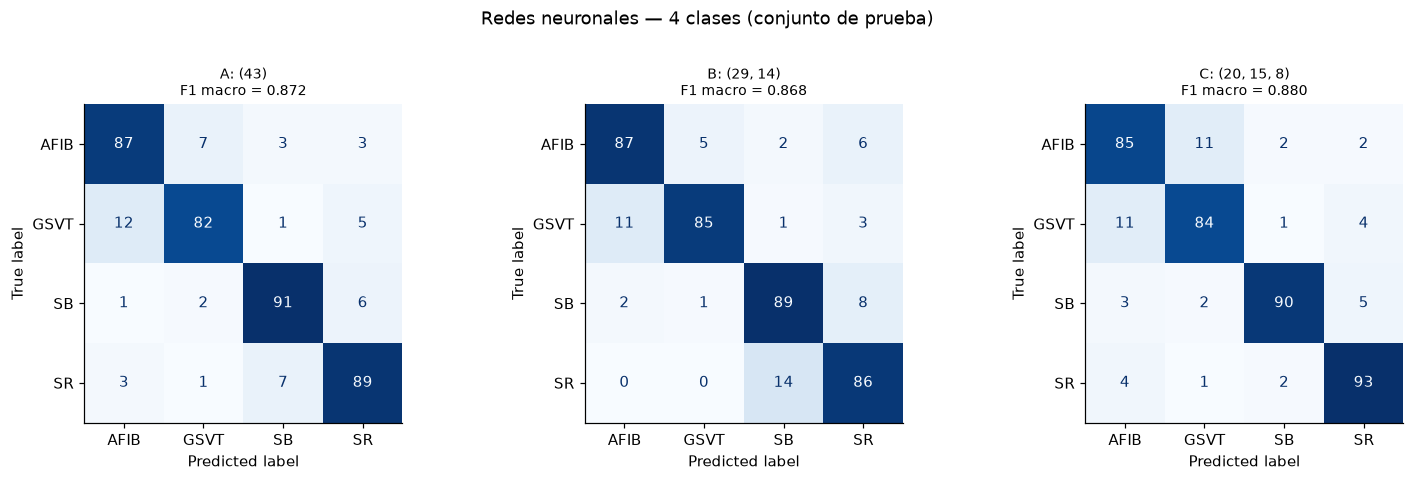

Mejor red: C: (20, 15, 8)
              precision    recall  f1-score   support

        AFIB      0.825     0.850     0.837       100
        GSVT      0.857     0.840     0.848       100
          SB      0.947     0.900     0.923       100
          SR      0.894     0.930     0.912       100

    accuracy                          0.880       400
   macro avg      0.881     0.880     0.880       400
weighted avg      0.881     0.880     0.880       400



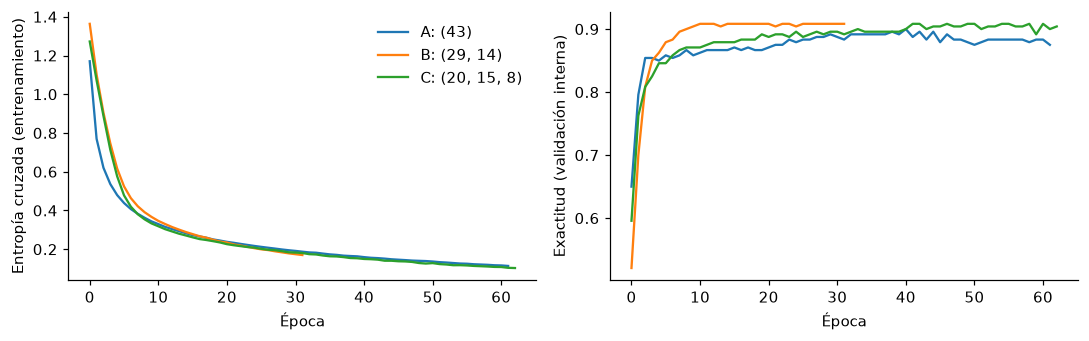

In [134]:
# ---------- Arquitecturas diseñadas con las reglas heurísticas ----------
n_in, n_out = Xtr.shape[1], len(CLASES)
n_oc = round(2 / 3 * n_in + n_out)                      # regla 2: (2/3)·59 + 4 ≈ 43
print(f"Entradas = {n_in} | salidas = {n_out} | neuronas ocultas sugeridas (regla 2) = {n_oc}")

ARQUITECTURAS = {"A: (43)": (43,), "B: (29, 14)": (29, 14), "C: (20, 15, 8)": (20, 15, 8)}
for nombre, capas in ARQUITECTURAS.items():
    tot = sum(capas)
    print(f"{nombre:16s} total ocultas = {tot} | regla 1 ({n_out} ≤ {tot} ≤ {n_in}): {n_out <= tot <= n_in} | regla 3 ({tot} < {2*n_in}): {tot < 2*n_in}")

def entrenar_mlp(Xtr, ytr, Xte, yte, ocultas, seed=SEMILLA):
    Xb, yb = sobremuestrear(Xtr, ytr, seed)
    t0 = time.perf_counter()
    m = MLPClassifier(hidden_layer_sizes=ocultas, activation="relu", solver="adam", alpha=1e-3, batch_size=64,
                      learning_rate_init=1e-3, max_iter=400, early_stopping=True, validation_fraction=0.15,
                      n_iter_no_change=20, random_state=seed).fit(Xb, yb)
    return m, m.predict(Xte), time.perf_counter() - t0

preds_nn, modelos_nn, filas_nn = {}, {}, []
for nombre, oc in ARQUITECTURAS.items():
    m, p, dt = entrenar_mlp(Xtr, ytr, Xte, yte, oc)
    preds_nn[nombre] = p; modelos_nn[nombre] = m
    # Exactitud en entrenamiento vs. prueba: si la de entrenamiento es mucho mayor, la red memorizó (sobreajuste)
    filas_nn.append({**evaluar(nombre, yte, p, CLASES),
                     "exactitud entrenamiento": accuracy_score(ytr, m.predict(Xtr)),
                     "épocas": m.n_iter_,
                     "parámetros": sum(w.size for w in m.coefs_) + sum(b.size for b in m.intercepts_),
                     "tiempo (s)": round(dt, 1)})
tabla_nn = pd.DataFrame(filas_nn).set_index("modelo"); display(tabla_nn.round(3))
graficar_matrices(preds_nn, [str(c) for c in le.classes_], yte, f"Redes neuronales — {len(CLASES)} clases (conjunto de prueba)")
mejor_nn = tabla_nn["F1 macro"].idxmax(); print("Mejor red:", mejor_nn)
print(classification_report(yte, preds_nn[mejor_nn], target_names=[str(c) for c in le.classes_], digits=3))

# Curvas de aprendizaje: pérdida de entrenamiento y exactitud de la validación interna (15 %) por época
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for n, m in modelos_nn.items():
    ax[0].plot(m.loss_curve_, label=n); ax[1].plot(m.validation_scores_, label=n)
ax[0].set_xlabel("Época"); ax[0].set_ylabel("Entropía cruzada (entrenamiento)")
ax[1].set_xlabel("Época"); ax[1].set_ylabel("Exactitud (validación interna)")
ax[0].legend(frameon=False); plt.tight_layout(); plt.show()

## Punto 5. Análisis: redes neuronales, cuatro clases

**Resultados en el conjunto de prueba (400 registros, 100 por clase):**

| Red | Exactitud prueba | F1 macro | Exactitud entrenamiento | Épocas | Parámetros |
|---|---|---|---|---|---|
| A (43) | 0,872 | 0,872 | 0,944 | 62 | 2756 |
| B (29, 14) | 0,868 | 0,868 | 0,896 | 32 | 2220 |
| C (20, 15, 8) | **0,880** | **0,880** | 0,946 | 63 | 1679 |

**Cómo se leen las métricas, con un ejemplo de la red C.** En la clase AFIB, la red acertó 85 de los 100 registros reales de AFIB ($TP=85$, $FN=15$), y predijo AFIB en 18 registros que no lo eran (11 de GSVT, 3 de SB y 4 de SR, $FP=18$). Entonces:

$$\text{Precisión}_{AFIB}=\frac{TP}{TP+FP}=\frac{85}{103}=0{,}825 \qquad \text{Sensibilidad}_{AFIB}=\frac{TP}{TP+FN}=\frac{85}{100}=0{,}850$$

$$F1_{AFIB}=2\cdot\frac{0{,}825\cdot 0{,}850}{0{,}825+0{,}850}=0{,}837$$

La precisión responde *"cuando la red dice AFIB, ¿cuántas veces acierta?"*, y la sensibilidad *"de todas las AFIB reales, ¿cuántas encontró?"*. El F1 macro es el promedio simple del F1 de las cuatro clases. Le da el mismo peso a cada clase, así que una clase mal clasificada baja el resultado aunque las demás estén bien.

**¿Cuál arquitectura es mejor?** La diferencia entre la mejor (C, 352 aciertos) y la peor (B, 347 aciertos) es de 5 registros, es decir 1,2 puntos. El error de muestreo de una exactitud de 0,88 medida en 400 registros es $\sqrt{0{,}88\cdot 0{,}12/400}\approx 0{,}016$, o sea ±1,6 puntos, mayor que esa diferencia. Por eso **las tres redes se consideran equivalentes**. Con el mismo número de neuronas ocultas (43), repartirlas en más capas no mejoró la clasificación. Se tomó la C como mejor red porque tiene el F1 macro más alto y el menor número de parámetros.

**Sobreajuste.** En las redes A y C la exactitud de entrenamiento (0,944 y 0,946) supera la de prueba en unos 7 puntos: las redes ajustan los datos de entrenamiento mejor de lo que generalizan. La curva de validación interna muestra que la exactitud se estabiliza alrededor de 0,88–0,91 desde la época 10–20, mientras la pérdida de entrenamiento sigue bajando. Lo que sigue aprendiendo la red después de ese punto ya no mejora la validación. La parada temprana corta el entrenamiento cuando la validación deja de mejorar; por eso la red B se detuvo antes (32 épocas) y tiene la menor diferencia entre entrenamiento y prueba (2,8 puntos).

**¿Dónde se equivocan las redes?** Hay dos confusiones principales:

| Red | Errores totales | AFIB ↔ GSVT | SB ↔ SR |
|---|---|---|---|
| A (43) | 51 | 19 (7 + 12) | 13 (6 + 7) |
| B (29, 14) | 53 | 16 (5 + 11) | 22 (8 + 14) |
| C (20, 15, 8) | 48 | 22 (11 + 11) | 7 (5 + 2) |

- **AFIB ↔ GSVT**: ambas son taquiarritmias, con frecuencia cardiaca alta, y en las dos la onda P es difícil de detectar (fracción de latidos con onda P: 0,33 en AFIB y 0,60 en GSVT, punto 4). Lo que más las separa es la irregularidad de los intervalos RR, que ayuda cuando la fibrilación es marcada pero no cuando el ritmo de AFIB es poco irregular.
- **SB ↔ SR**: las dos son ritmos sinusales con la misma morfología. Solo se diferencian por la frecuencia, con un umbral clínico de 60 lpm. Los registros cerca de ese umbral caen en una zona donde la red cambia de decisión según la arquitectura: la B confundió 22 y la C solo 7. Esa variación indica que la frontera entre ambas clases es inestable para las redes.

### 6. Redes neuronales — 2 clases (SR vs AFIB)

Se eligieron **ritmo sinusal (SR)** y **fibrilación auricular (AFIB)**: contrastan el ritmo normal con la arritmia sostenida más frecuente en la práctica clínica, que además aumenta el riesgo de accidente cerebrovascular. Sus diferencias fisiológicas, la irregularidad de los intervalos RR y la ausencia de onda P, son las más claras del conjunto de características (punto 4).

Se usan **las mismas tres arquitecturas** del punto 5, para comparar directamente el efecto de pasar de 4 a 2 clases. Siguen siendo coherentes con las reglas heurísticas: con 2 clases, la regla 2 da $\tfrac{2}{3}\cdot 59 + 2 \approx 41$ neuronas ocultas, muy cerca de las 43 usadas, y se siguen cumpliendo las reglas 1 ($2 \le 43 \le 59$) y 3 ($43 < 118$). En un problema binario, la salida se reduce a una sola neurona con función **sigmoide**, que da la probabilidad de AFIB:

$$\hat p = \sigma(z) = \frac{1}{1+e^{-z}}$$

Si $\hat p \ge 0{,}5$ se predice AFIB; si no, SR.

Además de la matriz de confusión se calcula el **área bajo la curva ROC (AUC)**. La curva ROC grafica la tasa de verdaderos positivos contra la de falsos positivos para todos los umbrales posibles:

$$TPR=\frac{TP}{TP+FN},\qquad FPR=\frac{FP}{FP+TN},\qquad \text{AUC}=\int_0^1 TPR\; d(FPR)$$

Un AUC de 1 significa separación perfecta, y uno de 0,5 equivale a clasificar al azar. A diferencia de la exactitud, el AUC no depende del umbral de 0,5: mide qué tan bien ordena el modelo los registros de AFIB por encima de los de SR.

SR vs AFIB | entrenamiento: 800 | prueba: 200


,exactitud,F1 macro,F1 ponderado,AUC-ROC,exactitud entrenamiento,épocas
modelo,,,,,,
A: (43),0.950,0.950,0.950,0.996,0.981,51
"B: (29, 14)",0.955,0.955,0.955,0.994,0.971,35
"C: (20, 15, 8)",0.950,0.950,0.950,0.994,0.986,53


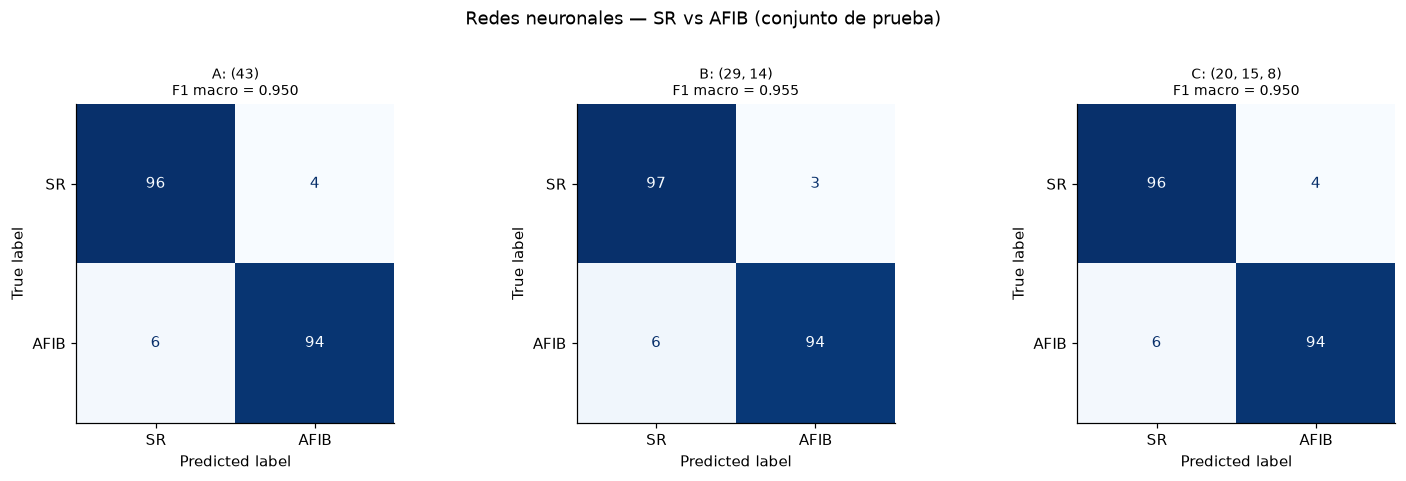

In [135]:
c0, c1 = PAR_BINARIO
assert c0 in le.classes_ and c1 in le.classes_, f"PAR_BINARIO debe estar en {[str(c) for c in le.classes_]}"
k0, k1 = le.transform([c0])[0], le.transform([c1])[0]
mtr, mte = np.isin(ytr, [k0, k1]), np.isin(yte, [k0, k1])
Xtr2, Xte2 = Xtr[mtr], Xte[mte]; ytr2, yte2 = (ytr[mtr] == k1).astype(int), (yte[mte] == k1).astype(int)
print(f"{c0} vs {c1} | entrenamiento: {Xtr2.shape[0]} | prueba: {Xte2.shape[0]}")

preds_2, filas_2 = {}, []
for nombre, oc in ARQUITECTURAS.items():
    m, p, dt = entrenar_mlp(Xtr2, ytr2, Xte2, yte2, oc)
    preds_2[nombre] = p
    auc = roc_auc_score(yte2, m.predict_proba(Xte2)[:, 1])
    filas_2.append({**evaluar(nombre, yte2, p, [c0, c1]), "AUC-ROC": auc,
                    "exactitud entrenamiento": accuracy_score(ytr2, m.predict(Xtr2)), "épocas": m.n_iter_})
tabla_2 = pd.DataFrame(filas_2).set_index("modelo"); display(tabla_2.round(3))
graficar_matrices(preds_2, [c0, c1], yte2, f"Redes neuronales — {c0} vs {c1} (conjunto de prueba)")

## Punto 6. Análisis: redes neuronales, SR vs AFIB

**Resultados en el conjunto de prueba (200 registros: 100 SR y 100 AFIB):**

| Red | Exactitud prueba | AUC-ROC | Exactitud entrenamiento | SR bien clasificados | AFIB bien clasificados |
|---|---|---|---|---|---|
| A (43) | 0,950 | 0,996 | 0,981 | 96/100 | 94/100 |
| B (29, 14) | **0,955** | 0,994 | 0,971 | 97/100 | 94/100 |
| C (20, 15, 8) | 0,950 | 0,994 | 0,986 | 96/100 | 94/100 |

**Sensibilidad y especificidad.** Tomando AFIB como la clase positiva (la que se quiere detectar), en las tres redes:

$$\text{Sensibilidad}=\frac{TP}{TP+FN}=\frac{94}{94+6}=0{,}94 \qquad \text{Especificidad}=\frac{TN}{TN+FP}=\frac{96}{96+4}=0{,}96 \;\;(0{,}97 \text{ en la red B})$$

La sensibilidad indica qué fracción de las fibrilaciones reales detecta la red, y la especificidad qué fracción de los ritmos normales reconoce como normales.

**Comparación entre arquitecturas.** Las tres redes cometen exactamente los mismos 6 falsos negativos (AFIB clasificada como SR), y solo difieren en los falsos positivos: 4, 3 y 4. La diferencia entre la mejor (B) y las otras es de un registro (0,5 puntos), muy por debajo del error de muestreo con 200 registros ($\sqrt{0{,}95\cdot 0{,}05/200}\approx \pm 1{,}5$ puntos). Las tres arquitecturas son equivalentes.

**¿Por qué el problema binario es más fácil?** La exactitud sube de 0,87–0,88 con cuatro clases a 0,95 con dos. Al dejar solo SR y AFIB desaparecen las dos confusiones que más errores causaban en el punto 5: AFIB con GSVT y SB con SR. Entre SR y AFIB las diferencias fisiológicas son claras. En AFIB el coeficiente de variación de los intervalos RR es unas nueve veces el de SR (0,189 frente a 0,021) y la fracción de latidos con onda P baja de 1,00 a 0,33 (punto 4). Un AUC de 0,994–0,996, cercano a 1, confirma que las dos clases son casi separables con estas características.

**Tipo de error y su importancia clínica.** En las tres redes hay más falsos negativos (6) que falsos positivos (3–4). Clínicamente, el falso negativo es el error más costoso: una fibrilación auricular no detectada no recibe anticoagulación y mantiene el riesgo de accidente cerebrovascular. Como el AUC (≈ 0,995) es mayor que la exactitud (0,95), bajar el umbral de decisión de 0,5 podría aumentar la sensibilidad a costa de unos pocos falsos positivos más. Esto no se probó en este trabajo.

**Sobreajuste.** La exactitud de entrenamiento (0,971–0,986) es de 2 a 4 puntos mayor que la de prueba, una diferencia menor que en el problema de cuatro clases. Con dos clases bien separadas, la red aprende una frontera que generaliza mejor.

**Limitaciones.** Cada cifra proviene de una única partición de prueba. Además, la muestra está balanceada (50 % AFIB), mientras que en la práctica la fibrilación auricular es mucho menos frecuente que el ritmo sinusal, así que en uso real la precisión (valor predictivo positivo) sería menor que la observada aquí.

### 7. XGBoost — 4 clases y comparación con la mejor red

**¿Qué es XGBoost?** Es un método de *gradient boosting* [16]: en lugar de un solo modelo grande, construye muchos **árboles de decisión pequeños, uno tras otro**, y cada árbol nuevo se entrena para corregir los errores que dejaron los anteriores. La predicción final es la suma de todos los árboles:

$$\hat y_i = \sum_{t=1}^{T} \eta\, f_t(x_i)$$

donde $f_t$ es el árbol número $t$, $T$ el número de árboles y $\eta$ la tasa de aprendizaje ($\eta=0{,}05$). Una $\eta$ pequeña hace que cada árbol corrija solo una parte del error, lo que da un modelo más estable. Con cuatro clases, en cada ronda se construye un árbol por clase, y las salidas se convierten en probabilidades con softmax, igual que en la red neuronal.

Cada árbol nuevo se elige para minimizar una función objetivo con dos partes, el error y un castigo por complejidad:

$$\mathcal{L}=\sum_{i=1}^{N}\ell\left(y_i,\hat y_i\right)+\sum_{t=1}^{T}\left(\gamma\, J_t+\tfrac{1}{2}\lambda\,\lVert w_t\rVert^2\right)$$

$\ell$ es la entropía cruzada (la misma pérdida de la red), $J_t$ el número de hojas del árbol y $w_t$ los valores de sus hojas. Los términos $\gamma$ y $\lambda$ ($\lambda = 1$) castigan los árboles grandes. Por eso XGBoost tiende a sobreajustar menos que un árbol de decisión simple.

**Configuración usada:**
- Árboles de profundidad máxima 4: cada árbol hace como máximo 4 preguntas seguidas del tipo *"¿rr_cv > 0,08?"*.
- `subsample = 0.8` y `colsample_bytree = 0.8`: cada árbol se entrena con el 80 % de los registros y el 80 % de las características, elegidos al azar. Esto agrega variedad y reduce el sobreajuste.
- **Parada temprana**: se separa el 15 % del entrenamiento como validación, y se dejan de agregar árboles cuando el error de validación no mejora en 30 rondas seguidas.
- `tree_method = "hist"`: agrupa los valores de cada característica en intervalos para encontrar los cortes más rápido.
- No necesita estandarizar las características, porque un árbol solo compara valores contra un umbral.

**Validación cruzada de 5 pliegues.** Una sola partición de prueba puede ser más fácil o más difícil por azar. Por eso, además, los 2000 registros se dividen en 5 partes estratificadas, el modelo se entrena 5 veces con 4 partes y se evalúa en la parte restante, y se reportan la media y la desviación estándar:

$$\overline{F1} = \frac{1}{5}\sum_{j=1}^{5} F1_{macro}^{(j)}$$

**Importancia de las características (ganancia media).** Cada vez que un árbol divide los datos usando una característica, la pérdida baja en una cantidad llamada *ganancia*. La importancia de una característica es el promedio de esa ganancia en todas las divisiones donde se usó. Una característica con ganancia alta produce divisiones que separan mucho mejor las clases.

XGBoost entrenado en 0.7 s (107 árboles)


,exactitud,F1 macro,F1 ponderado
modelo,,,
XGBoost,0.92,0.92,0.92
"Mejor red (C: (20, 15, 8))",0.88,0.88,0.88


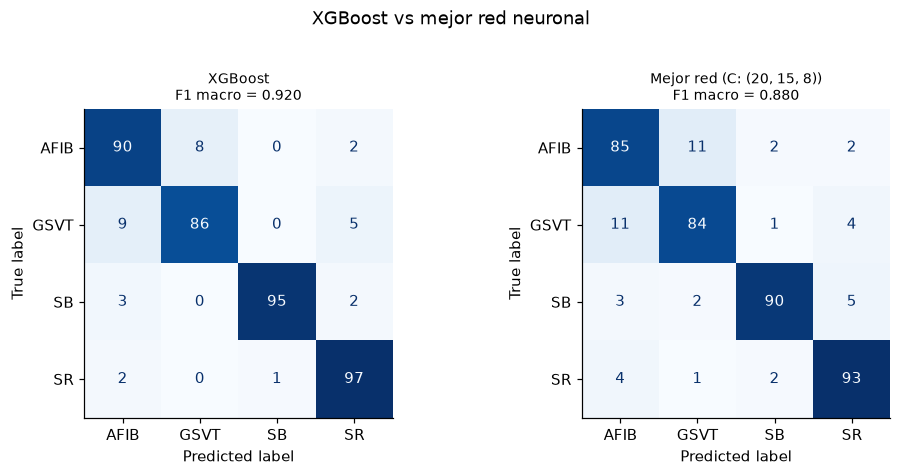

              precision    recall  f1-score   support

        AFIB      0.865     0.900     0.882       100
        GSVT      0.915     0.860     0.887       100
          SB      0.990     0.950     0.969       100
          SR      0.915     0.970     0.942       100

    accuracy                          0.920       400
   macro avg      0.921     0.920     0.920       400
weighted avg      0.921     0.920     0.920       400

XGBoost, F1 macro en 5 pliegues: 0.930 ± 0.008


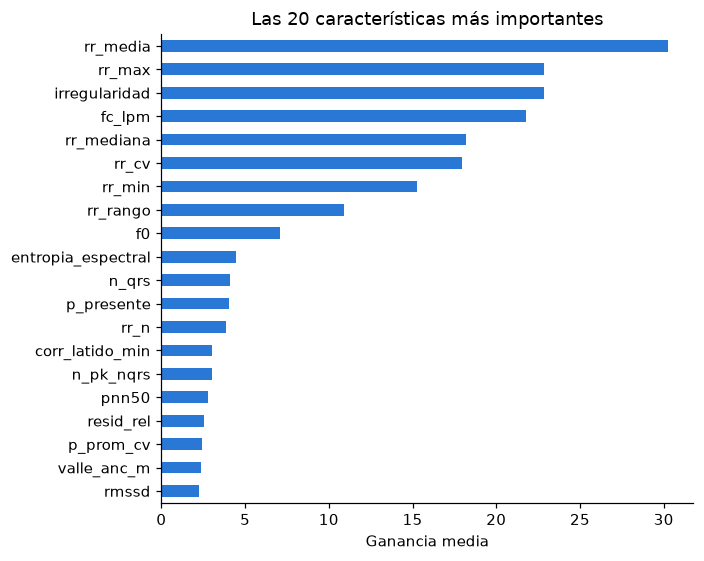

In [136]:
Xt, Xv, yt, yv = train_test_split(Xtr, ytr, test_size=0.15, stratify=ytr, random_state=SEMILLA)
def nuevo_xgb(n_estimators=600, **kw):
    return XGBClassifier(n_estimators=n_estimators, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                         min_child_weight=2, reg_lambda=1.0, tree_method="hist", n_jobs=-1, random_state=SEMILLA, **kw)

t0 = time.perf_counter()
xgb = nuevo_xgb(early_stopping_rounds=30, eval_metric="mlogloss")
xgb.fit(Xt, yt, sample_weight=compute_sample_weight("balanced", yt), eval_set=[(Xv, yv)], verbose=False)
p_xgb = xgb.predict(Xte); dt = time.perf_counter() - t0
print(f"XGBoost entrenado en {dt:.1f} s ({xgb.best_iteration + 1} árboles)")

comp = pd.DataFrame([evaluar("XGBoost", yte, p_xgb, CLASES), evaluar(f"Mejor red ({mejor_nn})", yte, preds_nn[mejor_nn], CLASES)]).set_index("modelo")
display(comp.round(3))
graficar_matrices({"XGBoost": p_xgb, f"Mejor red ({mejor_nn})": preds_nn[mejor_nn]}, [str(c) for c in le.classes_], yte, "XGBoost vs mejor red neuronal")
print(classification_report(yte, p_xgb, target_names=[str(c) for c in le.classes_], digits=3))

# Validación cruzada de 5 pliegues (el preprocesado se ajusta dentro de cada pliegue con un Pipeline)
from sklearn.pipeline import make_pipeline
cv = StratifiedKFold(5, shuffle=True, random_state=SEMILLA)
pipe_xgb = make_pipeline(SimpleImputer(strategy="median"), nuevo_xgb(eval_metric="mlogloss", n_estimators=250))
f1_cv = cross_val_score(pipe_xgb, X_all, y_all, cv=cv, scoring="f1_macro", n_jobs=1)
print(f"XGBoost, F1 macro en 5 pliegues: {f1_cv.mean():.3f} ± {f1_cv.std():.3f}")

imp_df = pd.Series(xgb.get_booster().get_score(importance_type="gain")).rename(lambda k: CARACTERISTICAS[int(k[1:])]).sort_values()
fig, ax = plt.subplots(figsize=(6.5, 5.2)); imp_df.tail(20).plot.barh(ax=ax, color="#2a78d6")
ax.set_xlabel("Ganancia media"); ax.set_title("Las 20 características más importantes"); plt.tight_layout(); plt.show()

## Punto 7. Análisis: XGBoost y comparación con la mejor red neuronal

**Resultados en el conjunto de prueba (los mismos 400 registros del punto 5):**

| Modelo | Exactitud | F1 macro | Aciertos |
|---|---|---|---|
| **XGBoost** (107 árboles) | **0,920** | **0,920** | 368/400 |
| Mejor red neuronal, C (20, 15, 8) | 0,880 | 0,880 | 352/400 |

Validación cruzada de 5 pliegues de XGBoost: **F1 macro = 0,930 ± 0,008**.

Matriz de confusión de XGBoost (filas: clase real; columnas: clase predicha):

| | AFIB | GSVT | SB | SR | Sensibilidad |
|---|---|---|---|---|---|
| **AFIB** | **90** | 8 | 0 | 2 | 0,90 |
| **GSVT** | 9 | **86** | 0 | 5 | 0,86 |
| **SB** | 3 | 0 | **95** | 2 | 0,95 |
| **SR** | 2 | 0 | 1 | **97** | 0,97 |
| **Precisión** | 0,865 | 0,915 | 0,990 | 0,915 | |

Por ejemplo, la precisión de AFIB es $90/(90+9+3+2)=90/104=0{,}865$: de cada 100 registros que XGBoost llama AFIB, unos 87 lo son.

**XGBoost frente a la red.** XGBoost acertó 16 registros más que la mejor red (4 puntos), y su sensibilidad es mayor en las cuatro clases (AFIB 0,90 frente a 0,85; GSVT 0,86 frente a 0,84; SB 0,95 frente a 0,90; SR 0,97 frente a 0,93). La diferencia es mayor que el error de muestreo de la prueba (±1,4–1,6 puntos). Además, la validación cruzada da un F1 macro estable (desviación de 0,008 entre pliegues), así que la ventaja no depende de una partición favorable. Como las redes no se evaluaron con validación cruzada, la comparación entre modelos se apoya en la partición de prueba común.

**¿Dónde mejora y dónde no?**
- **SB ↔ SR**: XGBoost confunde solo 3 registros (2 + 1), frente a 7 de la red C y 22 de la red B. Tiene sentido por cómo funciona cada modelo: SB y SR se separan por un umbral de frecuencia (60 lpm), y un árbol de decisión hace justamente eso, una pregunta del tipo *"¿rr_media > 1,0 s?"*. Una red con ReLU tiene que aproximar ese corte combinando neuronas, y cerca del umbral su decisión es menos estable.
- **AFIB ↔ GSVT**: sigue siendo la confusión principal (17 errores, 8 + 9), más de la mitad de los 32 errores de XGBoost. Que tanto las redes como XGBoost fallen en el mismo par indica que **el límite está en las características y no en el modelo**: con una sola derivación y a frecuencias altas, la onda P es difícil de medir, y la irregularidad de los intervalos RR no alcanza cuando la fibrilación es poco irregular.

**Importancia de las características.** Las nueve características con mayor ganancia media son todas de **ritmo**: `rr_media`, `rr_max`, `irregularidad`, `fc_lpm`, `rr_mediana`, `rr_cv`, `rr_min`, `rr_rango` y `f0`. Les siguen, con una ganancia mucho menor, la entropía espectral, el número de QRS y la presencia de onda P (`p_presente`). Es coherente con la clínica: SB, SR y GSVT se definen por la frecuencia, y la fibrilación auricular por la irregularidad. De las cinco características del Proyecto 1, solo `f0` aparece entre las 20 más importantes, porque las demás (fMP, sFSB) siguen indirectamente a la frecuencia cardiaca y no aportan información nueva cuando ya están los intervalos RR.

Hay dos precauciones para leer esta gráfica. Primero, varias características miden casi lo mismo: `rr_media`, `rr_mediana`, `fc_lpm` y `f0` tienen correlaciones en valor absoluto entre 0,90 y 0,99, y `f0` y `fc_lpm` están perfectamente correlacionadas ($r = 1{,}000$), porque son la misma medida en distintas unidades ($fc = 60\cdot f_0$). Cuando varias características llevan la misma información, la importancia se reparte entre ellas. Segundo, una ganancia baja no significa que la característica sea inútil: `p_presente` pesa poco porque la irregularidad RR ya separa la mayoría de las fibrilaciones y le deja poco por aportar.

**Ventajas prácticas de XGBoost en este problema:** entrena en menos de un segundo, no necesita estandarizar los datos ni elegir una arquitectura, y la importancia de las características permite interpretar qué usa el modelo para decidir.

### 8a. K-means (aprendizaje no supervisado)

**¿Qué hace?** K-means busca grupos (clústeres) en los datos **sin usar las etiquetas**. El algoritmo:

1. Elige $k$ centros iniciales $\mu_1,\dots,\mu_k$.
2. Asigna cada registro al centro más cercano, con distancia euclídea.
3. Recalcula cada centro como el promedio de los registros asignados: $\mu_j=\frac{1}{|C_j|}\sum_{x_i\in C_j}x_i$.
4. Repite los pasos 2 y 3 hasta que las asignaciones dejan de cambiar.

Con esto minimiza la **inercia**, la suma de distancias al cuadrado de cada registro a su centro:

$$J=\sum_{j=1}^{k}\sum_{x_i\in C_j}\lVert x_i-\mu_j\rVert^2$$

Como el resultado depende de los centros iniciales, se repite 20 veces con inicios distintos (`n_init = 20`) y se queda con la solución de menor inercia. Como usa distancias, las 59 características deben estar estandarizadas; si no, las de mayor escala dominarían la distancia.

**¿Cómo se elige $k$?** Se prueban $k$ entre 2 y 10 con dos criterios:
- **Método del codo**: la inercia siempre baja al aumentar $k$. Se busca el punto donde deja de bajar rápido (el "codo").
- **Coeficiente de silueta** [17]: para cada registro $i$, $a(i)$ es su distancia media a los registros de su propio clúster y $b(i)$ su distancia media al clúster vecino más cercano:

$$s(i)=\frac{b(i)-a(i)}{\max\{a(i),\,b(i)\}}, \qquad -1\le s(i)\le 1$$

  Un valor cercano a 1 indica que el registro está bien dentro de su clúster y lejos de los demás. Cerca de 0 indica que está en la frontera entre dos clústeres. Se reporta el promedio de todos los registros.

**¿Cómo se compara con las arritmias reales?** Solo al final se usan las etiquetas, con dos índices:
- **ARI (índice de Rand ajustado)** [18]: cuenta en cuántos pares de registros coinciden el agrupamiento y las etiquetas (los dos juntos o los dos separados), corregido por lo que se esperaría al azar. $ARI = 1$ es coincidencia perfecta y $ARI \approx 0$ equivale a agrupar al azar.

$$ARI=\frac{RI-E[RI]}{\max(RI)-E[RI]}$$

- **NMI (información mutua normalizada)**: mide cuánta información comparten los clústeres $C$ y las clases $Y$, entre 0 (nada) y 1 (lo mismo):

$$NMI=\frac{2\,I(Y;C)}{H(Y)+H(C)}$$

Para visualizar, los 2000 registros se proyectan en las dos primeras **componentes principales (PCA)**, las dos direcciones de mayor varianza de los datos estandarizados.

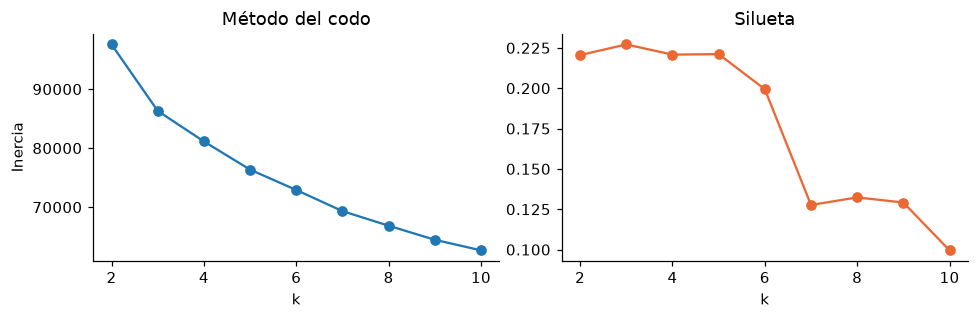

k = 4 (número de arritmias) | ARI = 0.475 | NMI = 0.522 | silueta = 0.218


Clúster,0,1,2,3
Arritmia real,,,,
AFIB,12,391,55,42
GSVT,8,60,417,15
SB,1,20,0,479
SR,0,31,2,467


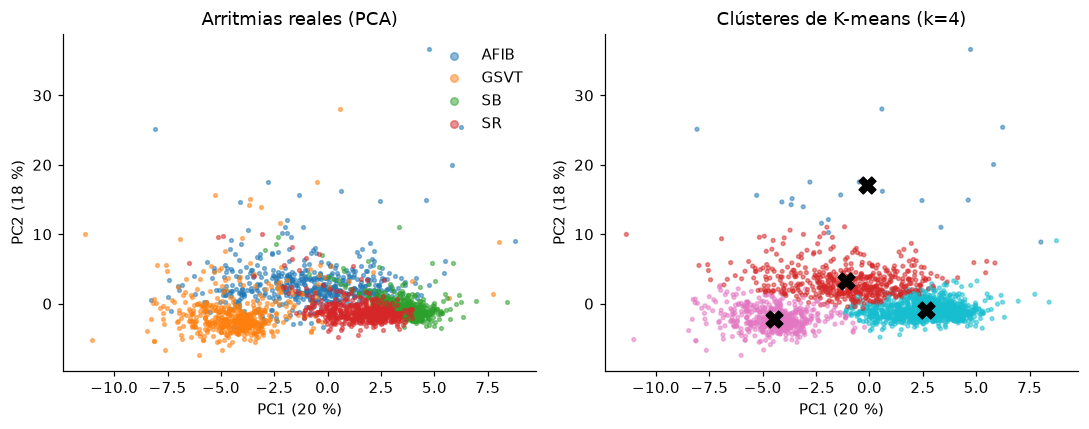

In [137]:
Xs = prep(X_all)
ks = range(2, 11)
inercia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(Xs)
    inercia.append(km.inertia_); sil.append(silhouette_score(Xs, km.labels_, sample_size=2000, random_state=SEMILLA))
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot(list(ks), inercia, "o-"); ax[0].set_title("Método del codo"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inercia")
ax[1].plot(list(ks), sil, "o-", color="#eb6834"); ax[1].set_title("Silueta"); ax[1].set_xlabel("k"); plt.tight_layout(); plt.show()

K = len(CLASES)
km = KMeans(n_clusters=K, n_init=20, random_state=SEMILLA).fit(Xs)
print(f"k = {K} (número de arritmias) | ARI = {adjusted_rand_score(y_all, km.labels_):.3f} | NMI = {normalized_mutual_info_score(y_all, km.labels_):.3f} | silueta = {silhouette_score(Xs, km.labels_, sample_size=2000, random_state=SEMILLA):.3f}")
display(pd.crosstab(pd.Series(le.inverse_transform(y_all), name="Arritmia real"), pd.Series(km.labels_, name="Clúster")))

pca = PCA(n_components=2, random_state=SEMILLA).fit(Xs); Z = pca.transform(Xs)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for k_, c in enumerate([str(c) for c in le.classes_]): ax[0].scatter(*Z[y_all == k_].T, s=6, alpha=0.5, label=c)
ax[0].legend(markerscale=2, frameon=False); ax[0].set_title("Arritmias reales (PCA)")
ax[1].scatter(*Z.T, c=km.labels_, s=6, alpha=0.5, cmap="tab10"); ax[1].scatter(*pca.transform(km.cluster_centers_).T, c="k", marker="X", s=120)
ax[1].set_title(f"Clústeres de K-means (k={K})")
for a in ax: a.set_xlabel(f"PC1 ({100*pca.explained_variance_ratio_[0]:.0f} %)"); a.set_ylabel(f"PC2 ({100*pca.explained_variance_ratio_[1]:.0f} %)")
plt.tight_layout(); plt.show()

## Punto 8a. Análisis: K-means

**Elección de $k$.** La inercia baja de forma continua al aumentar $k$, de unos 97 500 con $k=2$ a unos 81 000 con $k=4$ y unos 62 700 con $k=10$, **sin un codo claro**: solo baja algo más rápido entre $k=2$ y $k=3$. La silueta se mantiene baja y casi constante entre $k=2$ y $k=5$ (0,22–0,23), baja a 0,20 en $k=6$ y cae a 0,10–0,13 desde $k=7$. Ninguno de los dos criterios señala un número natural de grupos: **los datos no forman clústeres bien separados**. Se usó $k=4$ para poder comparar los grupos con las cuatro arritmias.

**Resultados con $k=4$:** ARI = 0,475, NMI = 0,522, silueta = 0,218.

| Arritmia real | Clúster 0 | Clúster 1 | Clúster 2 | Clúster 3 |
|---|---|---|---|---|
| AFIB | 12 | **391** | 55 | 42 |
| GSVT | 8 | 60 | **417** | 15 |
| SB | 1 | 20 | 0 | **479** |
| SR | 0 | 31 | 2 | **467** |
| **Total** | 21 | 502 | 474 | 1003 |

**¿Qué encontró K-means?**
- **Clúster 1 ≈ AFIB**: reúne 391 de los 500 registros de AFIB, y el 78 % de sus 502 registros son AFIB.
- **Clúster 2 ≈ GSVT**: reúne 417 de los 500 de GSVT, y el 88 % de sus 474 registros son GSVT.
- **Clúster 3 = SB y SR juntos**: contiene 479 SB y 467 SR (el 94 % del clúster). K-means **no separa la bradicardia del ritmo sinusal**.
- **Clúster 0**: solo 21 registros, que en la gráfica PCA aparecen lejos del resto (PC2 > 10). Son probablemente registros atípicos o con artefactos, y no una arritmia.

**¿Por qué no separa SB de SR?** Las dos clases tienen la misma morfología y la misma regularidad. Solo se diferencian en la frecuencia (medianas de 56 y 73 lpm), y el corte entre ellas es un umbral clínico de 60 lpm, no un hueco natural en los datos. K-means agrupa por distancia en las 59 características a la vez, y esa diferencia de frecuencia es pequeña frente a la variación de las demás, así que no alcanza para formar dos grupos.

**Comparación con los modelos supervisados.** Si a cada clúster se le asigna su clase mayoritaria (0 → AFIB, 1 → AFIB, 2 → GSVT, 3 → SB), se aciertan $12+391+417+479=1299$ de 2000 registros, el **65 %**. SR queda sin clúster propio. Los modelos supervisados lograron entre el 87 % y el 92 %. La diferencia muestra el valor de las etiquetas: un modelo supervisado aprende exactamente la frontera que define el diagnóstico (por ejemplo, el corte de 60 lpm), mientras que K-means solo encuentra la estructura más marcada de los datos.

**Lectura de la gráfica PCA.** Las dos primeras componentes explican solo el 38 % de la varianza (20 % + 18 %), así que la gráfica es una vista parcial. Aun así, se ve la misma organización: GSVT a la izquierda (frecuencia alta y ritmo regular), SB y SR superpuestos a la derecha, y AFIB dispersa hacia arriba (irregularidad).

**Utilidad.** K-means sirve aquí como **análisis exploratorio**: confirma que la frecuencia y la irregularidad son los ejes naturales de los datos. No sirve como clasificador de las cuatro arritmias.

### 8b. Máquinas de soporte vectorial (SVM)

**¿Qué hace?** Para dos clases, con etiquetas $y_i\in\{-1,+1\}$, la SVM busca el hiperplano $w^\top x+b=0$ que las separa dejando el **mayor margen** posible [19], es decir, la mayor distancia entre el hiperplano y los registros más cercanos de cada clase. Esos registros más cercanos se llaman **vectores de soporte**: son los únicos que definen la frontera. Si se quitara cualquier otro registro, el hiperplano no cambiaría.

El margen mide $2/\lVert w\rVert$, así que maximizarlo equivale a minimizar $\lVert w\rVert^2$. Como en datos reales las clases se solapan, se permite que algunos registros queden del lado equivocado, con una holgura $\xi_i\ge 0$:

$$\min_{w,\,b,\,\xi}\ \ \frac{1}{2}\lVert w\rVert^2 + C\sum_{i=1}^{N}\xi_i \qquad \text{sujeto a}\quad y_i\left(w^\top\phi(x_i)+b\right)\ge 1-\xi_i$$

**C** controla el equilibrio entre margen y errores. Con C alto se castigan mucho los errores de entrenamiento: el margen queda estrecho y hay riesgo de sobreajuste. Con C bajo se tolera más error a cambio de un margen ancho y una frontera más simple.

**Kernel.** Si las clases no se separan con una frontera recta, la función $\phi$ lleva los datos a un espacio de mayor dimensión donde sí se puedan separar. No hace falta calcular $\phi$ directamente: basta con un **kernel**, que mide la similitud entre dos registros. Se usa el kernel **RBF (gaussiano)**:

$$K(x,x')=\exp\left(-\gamma\,\lVert x-x'\rVert^2\right)$$

**γ** controla qué tan local es la influencia de cada registro. Con γ alto, cada registro solo influye en su vecindad inmediata y la frontera puede volverse muy irregular (sobreajuste). Con γ bajo, la influencia es amplia y la frontera es suave. Como comparación se entrena también una SVM con **kernel lineal**, $K(x,x')=x^\top x'$, que solo permite fronteras rectas.

**Configuración:**
- **Más de dos clases**: se entrena una SVM por cada par de clases, 6 pares para 4 clases (esquema *uno contra uno*), y gana la clase que obtiene más votos.
- **Búsqueda de hiperparámetros**: se prueban $C\in\{1,10,100\}$ y $\gamma\in\{\text{scale},\,0{,}01,\,0{,}003\}$, con validación cruzada de 3 pliegues **solo sobre el conjunto de entrenamiento**. La prueba no se usa para elegir, y así sigue siendo una evaluación honesta. Con `gamma = "scale"`, sklearn usa $\gamma = 1/(n_{caract}\cdot \text{Var}(X))$.
- Las características están estandarizadas, porque el kernel depende de distancias.

Mejores hiperparámetros: {'C': 10, 'gamma': 0.003} | 0.4 s | vectores de soporte: 553 de 1600


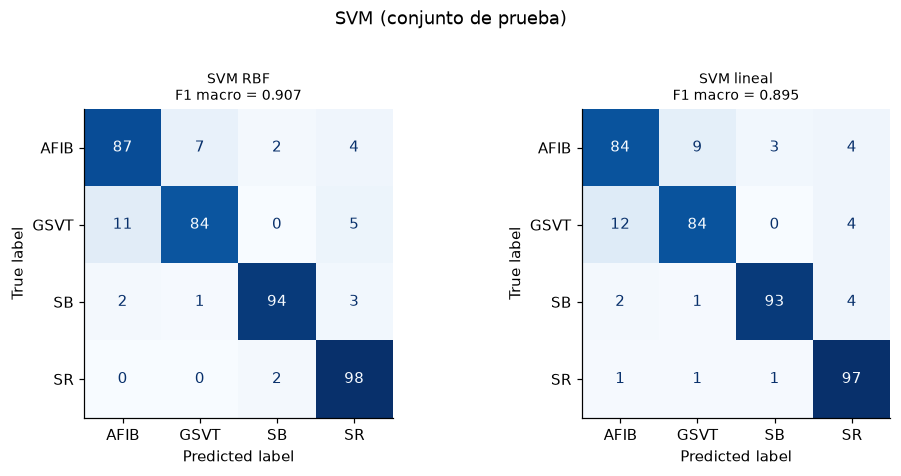

              precision    recall  f1-score   support

        AFIB      0.870     0.870     0.870       100
        GSVT      0.913     0.840     0.875       100
          SB      0.959     0.940     0.949       100
          SR      0.891     0.980     0.933       100

    accuracy                          0.907       400
   macro avg      0.908     0.907     0.907       400
weighted avg      0.908     0.907     0.907       400



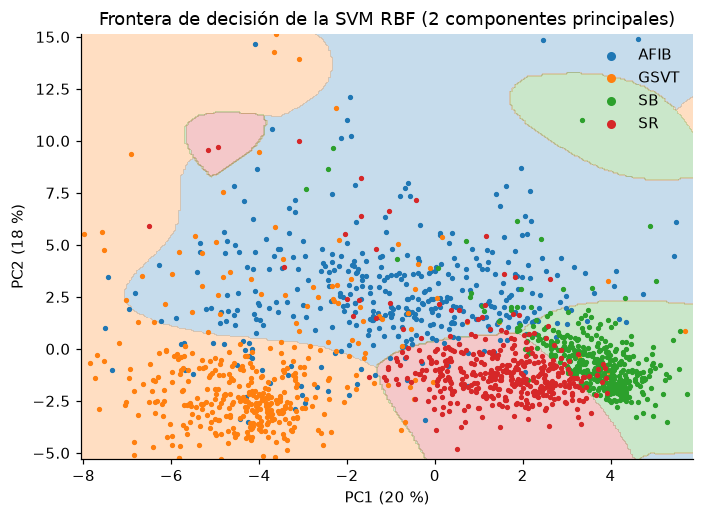

Exactitud de la SVM con solo 2 componentes (prueba): 0.828  (con las 59 características: 0.907)


In [138]:
t0 = time.perf_counter()
grid = GridSearchCV(SVC(kernel="rbf", class_weight="balanced"), {"C": [1, 10, 100], "gamma": ["scale", 0.01, 0.003]},
                    cv=StratifiedKFold(3, shuffle=True, random_state=SEMILLA), scoring="f1_macro", n_jobs=-1).fit(Xtr, ytr)
svm = grid.best_estimator_; p_svm = svm.predict(Xte)
print(f"Mejores hiperparámetros: {grid.best_params_} | {time.perf_counter()-t0:.1f} s | vectores de soporte: {svm.n_support_.sum()} de {len(Xtr)}")
svm_lin = SVC(kernel="linear", class_weight="balanced", C=1).fit(Xtr, ytr); p_lin = svm_lin.predict(Xte)
graficar_matrices({"SVM RBF": p_svm, "SVM lineal": p_lin}, [str(c) for c in le.classes_], yte, "SVM (conjunto de prueba)")
print(classification_report(yte, p_svm, target_names=[str(c) for c in le.classes_], digits=3))

# Frontera de decisión en 2D (solo para visualizar: SVM entrenada con las 2 primeras componentes principales)
from matplotlib.colors import ListedColormap
colores = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"][:len(CLASES)]   # el mismo color por clase en el fondo y en los puntos
cmap_clases = ListedColormap(colores)

Ztr, Zte = pca.transform(Xtr), pca.transform(Xte)
svm2d = SVC(kernel="rbf", C=grid.best_params_["C"], gamma="scale", class_weight="balanced").fit(Ztr, ytr)
gx, gy = np.meshgrid(np.linspace(*np.percentile(Z[:, 0], [0.5, 99.5]), 250),
                     np.linspace(*np.percentile(Z[:, 1], [0.5, 99.5]), 250))
zona = svm2d.predict(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)

fig, ax = plt.subplots(figsize=(6.5, 4.8))
ax.contourf(gx, gy, zona, alpha=0.25, cmap=cmap_clases, levels=np.arange(-0.5, len(CLASES) + 0.5))
for k_, c in enumerate(le.classes_):
    ax.scatter(*Ztr[ytr == k_].T, s=6, color=colores[k_], label=str(c))
ax.set_xlim(gx.min(), gx.max()); ax.set_ylim(gy.min(), gy.max())
ax.set_xlabel(f"PC1 ({100*pca.explained_variance_ratio_[0]:.0f} %)"); ax.set_ylabel(f"PC2 ({100*pca.explained_variance_ratio_[1]:.0f} %)")
ax.legend(markerscale=2, frameon=False, loc="upper right")
ax.set_title("Frontera de decisión de la SVM RBF (2 componentes principales)"); plt.tight_layout(); plt.show()
print(f"Exactitud de la SVM con solo 2 componentes (prueba): {accuracy_score(yte, svm2d.predict(Zte)):.3f}  "
      f"(con las 59 características: {accuracy_score(yte, p_svm):.3f})")

## Punto 8b. Análisis: SVM

**Hiperparámetros elegidos:** $C = 10$ y $\gamma = 0{,}003$. Con las características estandarizadas, la opción `scale` equivale a $\gamma \approx 1/59 \approx 0{,}017$, así que el $\gamma$ elegido es unas seis veces menor: un kernel muy suave, donde cada registro influye sobre una región amplia. El modelo quedó con 553 vectores de soporte de 1600 registros de entrenamiento (35 %).

| Modelo | Exactitud | F1 macro | Aciertos |
|---|---|---|---|
| SVM RBF | 0,908 | 0,907 | 363/400 |
| SVM lineal ($C=1$) | 0,895 | 0,895 | 358/400 |

Matriz de confusión de la SVM RBF (filas: clase real; columnas: clase predicha):

| | AFIB | GSVT | SB | SR | Sensibilidad |
|---|---|---|---|---|---|
| **AFIB** | **87** | 7 | 2 | 4 | 0,87 |
| **GSVT** | 11 | **84** | 0 | 5 | 0,84 |
| **SB** | 2 | 1 | **94** | 3 | 0,94 |
| **SR** | 0 | 0 | 2 | **98** | 0,98 |

**Kernel RBF frente a lineal.** El kernel RBF acierta solo 5 registros más que el lineal (1,25 puntos), una diferencia menor que el error de muestreo. Junto con el $\gamma$ pequeño elegido por la validación cruzada, esto indica que **las clases son casi separables con fronteras lineales** en el espacio de las 59 características, y que la no linealidad aporta poco. Tiene sentido, porque varias características (frecuencia, coeficiente de variación de RR) ya separan las clases casi directamente.

**Errores.** Se repite el patrón de los demás modelos: la confusión AFIB ↔ GSVT concentra 18 de los 37 errores (7 + 11). Entre SB y SR la SVM comete solo 5 errores (3 + 2), muchos menos que la red A (13) o la B (22), y cerca de XGBoost (3).

**Vectores de soporte.** Que el 35 % de los registros de entrenamiento sean vectores de soporte indica que muchos registros quedan cerca de las fronteras o del lado equivocado. Las clases se solapan, sobre todo AFIB y GSVT. Si las clases estuvieran bien separadas, bastarían pocos vectores de soporte.

**Frontera en dos dimensiones.** La gráfica muestra una SVM entrenada solo con las dos primeras componentes principales, para poder dibujarla. GSVT (abajo a la izquierda) y el grupo SB/SR (abajo a la derecha) ocupan zonas bien definidas, mientras AFIB queda en la zona superior, mezclada con registros de GSVT. Con solo esas dos componentes la exactitud baja a 0,828, frente a 0,907 con las 59 características. La gráfica ilustra cómo trabaja el modelo, pero el modelo real usa información que no cabe en dos dimensiones.

**SVM frente a los demás modelos.** La SVM RBF (363 aciertos) queda entre XGBoost (368) y la mejor red neuronal (352). Frente a XGBoost la diferencia es de 5 registros, dentro del error de muestreo, así que los dos son equivalentes en esta partición. Frente a K-means (65 % de acierto con la asignación por mayoría), usar las etiquetas para ajustar la frontera mejora el resultado en unos 26 puntos.

## Resumen de resultados (conjunto de prueba, 4 clases, 400 registros)

In [139]:
resumen = pd.DataFrame(
    [evaluar(f"Red {n}", yte, p, CLASES) for n, p in preds_nn.items()] +
    [evaluar("XGBoost", yte, p_xgb, CLASES), evaluar("SVM RBF", yte, p_svm, CLASES), evaluar("SVM lineal", yte, p_lin, CLASES)]
).set_index("modelo").round(3)
display(resumen)
print(f"K-means (no supervisado): ARI = {adjusted_rand_score(y_all, km.labels_):.3f}")
resumen.to_csv(cache("resumen_modelos.csv"))

,exactitud,F1 macro,F1 ponderado
modelo,,,
Red A: (43),0.872,0.872,0.872
"Red B: (29, 14)",0.868,0.868,0.868
"Red C: (20, 15, 8)",0.880,0.880,0.880
XGBoost,0.920,0.920,0.920
SVM RBF,0.908,0.907,0.907
SVM lineal,0.895,0.895,0.895


K-means (no supervisado): ARI = 0.475


## Comparación de los modelos implementados

| Modelo | Tipo | Exactitud | F1 macro | Aciertos (de 400) |
|---|---|---|---|---|
| XGBoost | Supervisado, árboles | **0,920** | **0,920** | 368 |
| SVM RBF | Supervisado, kernel | 0,908 | 0,907 | 363 |
| SVM lineal | Supervisado, lineal | 0,895 | 0,895 | 358 |
| Red C (20, 15, 8) | Supervisado, red neuronal | 0,880 | 0,880 | 352 |
| Red A (43) | Supervisado, red neuronal | 0,872 | 0,872 | 349 |
| Red B (29, 14) | Supervisado, red neuronal | 0,868 | 0,868 | 347 |
| K-means ($k=4$) | No supervisado | 0,650* | — | 1299 de 2000* |

\* K-means no se entrena con etiquetas. Su "exactitud" se obtiene asignando a cada clúster su clase mayoritaria, sobre los 2000 registros (ARI = 0,475).

**Lectura de la tabla.**
- **Hay tres niveles.** XGBoost y la SVM RBF forman el grupo de mejor desempeño (0,908–0,920; su diferencia de 5 registros está dentro del error de muestreo de ±1,4 puntos). La SVM lineal y las redes neuronales quedan entre 0,868 y 0,895. K-means queda muy por debajo (65 %).
- **Todos los modelos supervisados fallan en lo mismo.** La confusión AFIB ↔ GSVT es la principal fuente de error en todos ellos (entre 16 y 22 registros), independientemente de que sean árboles, kernels o redes. Esto indica que el límite está en la información que contienen las características de una sola derivación, y no en el clasificador.
- **SB ↔ SR separa a los modelos.** XGBoost (3 errores) y la SVM (5) separan bien estas clases, mientras que las redes varían mucho según la arquitectura (de 7 a 22). La diferencia entre SB y SR es un umbral de frecuencia, que un árbol representa con una sola división y que a una red le cuesta más aproximar.
- **Más complejidad no implicó mejores resultados.** La SVM lineal superó a las tres redes, y entre las redes la de menos parámetros (C, 1679) fue la mejor. Con 59 características diseñadas a mano y 1600 registros de entrenamiento, los modelos simples ya capturan casi toda la estructura disponible.

**Limitación.** Todas las cifras de prueba vienen de una única partición de 400 registros; solo XGBoost se evaluó además con validación cruzada (F1 macro = 0,930 ± 0,008).

## 9. Informe

### 9.1. Equipos comerciales con algoritmos de ayuda diagnóstica

Se consultaron tres equipos comerciales que incorporan algoritmos de análisis electrocardiográfico, los cuales representan diferentes niveles de complejidad en la adquisición y procesamiento de señales ECG: un dispositivo portátil de una derivación, un dispositivo personal de seis derivaciones y un sistema clínico de doce derivaciones. Los fabricantes no publican completamente el funcionamiento interno de sus algoritmos, por lo que la descripción se basa en las funcionalidades declaradas en su documentación oficial.

#### 9.1.1. Apple Watch – Aplicación ECG

La aplicación ECG del Apple Watch permite registrar durante 30 segundos una señal electrocardiográfica de un solo canal, similar a la derivación I. A partir del registro, clasifica la señal como ritmo sinusal o fibrilación auricular (FA), siempre que la grabación sea clasificable. En versiones posteriores se incorporó una categoría de frecuencia cardíaca elevada sin detección de FA, para frecuencias entre 100 y 150 lpm. Cuando la señal no cumple los criterios necesarios para una clasificación, el dispositivo genera un resultado no concluyente [20].

En sus primeras versiones, las frecuencias cardíacas inferiores a 50 lpm o superiores a 120 lpm podían dificultar la detección de fibrilación auricular y producir resultados no concluyentes. En 2018, la FDA autorizó dos aplicaciones de análisis del ritmo cardíaco para el Apple Watch: el registro ECG de 30 segundos y un sistema de análisis del pulso que genera alertas ante posibles episodios de fibrilación auricular [21].

En una validación clínica realizada con aproximadamente 600 sujetos, la aplicación reportó una sensibilidad del 98,3 % para fibrilación auricular y una especificidad del 99,6 % para ritmo sinusal en las grabaciones clasificables. Sin embargo, el 12,2 % de las grabaciones fue considerado no concluyente. Al incluir estos registros en el análisis, se clasificó correctamente el 90,5 % de los sujetos con ritmo sinusal y el 85,2 % de los sujetos con fibrilación auricular. El dispositivo está destinado a personas de 22 años o más y no se recomienda para individuos con otras arritmias conocidas [20].

#### 9.1.2. AliveCor KardiaMobile 6L

El KardiaMobile 6L es un dispositivo portátil que permite adquirir un electrocardiograma de seis derivaciones durante aproximadamente 30 segundos. Las derivaciones registradas son I, II, III, aVL, aVR y aVF, lo que proporciona mayor información electrocardiográfica que un dispositivo de una sola derivación [22].

El dispositivo incorpora algoritmos de inteligencia artificial autorizados por la FDA para identificar seis alteraciones del ritmo: fibrilación auricular, bradicardia, taquicardia, ritmo sinusal con extrasístoles ventriculares, ritmo sinusal con QRS ancho y ritmo sinusal con extrasístoles supraventriculares [23].

En la autorización de noviembre de 2020, el QRS ancho se definió mediante complejos con duración igual o superior a 120 ms, mientras que la detección de extrasístoles ventriculares requería la identificación de dos o más latidos ectópicos. El dispositivo no está probado ni recomendado para personas con marcapasos o desfibriladores y no está diseñado para detectar infartos [23].

#### 9.1.3. GE HealthCare – Programa Marquette 12SL

El Marquette 12SL es un programa de análisis electrocardiográfico empleado en electrocardiógrafos clínicos de GE HealthCare, como los equipos MAC y el sistema MUSE. Este sistema analiza ECG de 12 y 15 derivaciones y proporciona mediciones de frecuencia cardíaca, eje eléctrico, intervalos y duraciones, además de interpretaciones automatizadas que sirven como apoyo al diagnóstico clínico [24].

Entre sus funcionalidades se encuentran el análisis de arritmias auriculares, la detección de actividad de marcapasos, la evaluación del intervalo QT y la verificación de la calidad del registro. Su procesamiento incluye la medición de características de las ondas y la interpretación de patrones de ritmo y morfología para generar enunciados diagnósticos.

El sistema delimita los inicios y finales de las ondas principales mediante el análisis de sus pendientes en múltiples derivaciones. Para la medición del intervalo QT utiliza un complejo mediano, lo que contribuye a reducir la influencia del ruido. Adicionalmente, cuenta con criterios específicos según edad, sexo y población pediátrica [24].

Los nombres de los registros empleados en este proyecto (MUSE_...) sugieren que la base de datos utilizada está asociada a registros provenientes de sistemas de electrocardiografía clínica de este tipo.

---

### 9.2. Comparación de los equipos comerciales

| Característica | Apple Watch (ECG) | KardiaMobile 6L | Marquette 12SL |
|---|---|---|---|
| Derivaciones | Una, similar a I | Seis: I, II, III, aVL, aVR y aVF | 12 o 15 |
| Duración del registro | 30 segundos | 30 segundos | Registro clínico estándar |
| Resultados | Ritmo sinusal, FA, frecuencia elevada y no concluyente | FA, bradicardia, taquicardia, extrasístoles y QRS ancho | Mediciones, análisis de ritmo y morfología, QT y actividad de marcapasos |
| Usuario principal | Persona no especialista | Persona y profesional de salud | Profesional de salud |
| Aplicación | Monitoreo personal | Monitoreo personal y apoyo diagnóstico | Análisis clínico |

---

### 9.3. Discusión desde la teoría del curso

#### 9.3.1. Adquisición y número de derivaciones

La información obtenida a partir de un ECG depende del número de derivaciones disponibles. Una sola derivación permite estudiar principalmente características relacionadas con el ritmo y la regularidad de los latidos, mientras que un sistema multiderivación proporciona información adicional sobre la actividad eléctrica cardíaca, incluyendo el eje eléctrico y aspectos relacionados con la morfología y localización de alteraciones.

Esta diferencia explica las funcionalidades de los equipos comparados. El Apple Watch, al utilizar una señal de un solo canal, se concentra principalmente en la identificación de fibrilación auricular y ritmo sinusal. Por su parte, los dispositivos de seis y doce derivaciones disponen de mayor información para realizar análisis más amplios.

En el presente proyecto se trabajó exclusivamente con la derivación II, que permite observar componentes importantes del ECG, como las ondas P, los complejos QRS y las ondas T, además de estudiar las características relacionadas con la frecuencia cardíaca y la variabilidad de los intervalos RR.

#### 9.3.2. Preprocesamiento y calidad de la señal

El análisis automatizado de ECG requiere etapas de preprocesamiento para reducir la influencia del ruido, las fluctuaciones de la línea base y otros artefactos que pueden afectar la identificación de características. Estas etapas son fundamentales para mejorar la calidad de la señal antes de realizar el análisis o la clasificación.

En este proyecto se implementó un flujo de procesamiento basado en filtros Butterworth, corrección de línea base mediante LOESS y reducción de ruido mediante Non-Local Means (NLM). Estas etapas buscan mejorar la calidad de las señales y facilitar la extracción de características.

Los equipos comerciales también incorporan mecanismos para gestionar registros de calidad insuficiente. Por ejemplo, el Apple Watch genera resultados no concluyentes cuando la señal no permite realizar una clasificación confiable, mientras que el Marquette 12SL incorpora mecanismos de verificación de calidad del registro.

De manera similar, durante el desarrollo de este proyecto se identificaron registros en los que el detector de picos R presentó dificultades para identificar los latidos, lo que evidencia la importancia de implementar mecanismos robustos de detección y control de calidad.

#### 9.3.3. Extracción de características y estructura del algoritmo

Los sistemas automatizados de análisis electrocardiográfico pueden entenderse mediante dos etapas principales: una etapa de medición y extracción de características, y una etapa de interpretación de dichas características para generar una clasificación o enunciado diagnóstico.

Esta estructura es similar a la implementada en el presente proyecto, donde inicialmente se realiza el procesamiento de la señal y posteriormente se extraen características relacionadas con la morfología, frecuencia y regularidad cardíaca, que son utilizadas por los modelos de clasificación.

Las funcionalidades de los equipos comerciales pueden relacionarse conceptualmente con algunas de las características calculadas en el proyecto. Por ejemplo, la frecuencia cardíaca permite identificar patrones asociados con bradicardia y taquicardia; la duración del complejo QRS permite analizar patrones de QRS ancho; mientras que la regularidad de los intervalos RR y la detección de ondas P pueden aportar información para identificar fibrilación auricular.

En los resultados del proyecto, las características relacionadas con el ritmo, como `rr_media`, `rr_cv` e `irregularidad`, mostraron relevancia para la clasificación mediante XGBoost. Esto evidencia la importancia de las características temporales asociadas a los intervalos RR en la diferenciación de los ritmos cardíacos estudiados.

Sin embargo, la relación entre las funcionalidades comerciales y las características implementadas en este proyecto es una comparación conceptual. Los fabricantes no necesariamente utilizan las mismas características ni los mismos algoritmos internos.

#### 9.3.4. Clasificación y validación

Los equipos comerciales reportan métricas de desempeño obtenidas mediante procesos de validación clínica, generalmente comparando sus resultados con diagnósticos de referencia. Estas métricas permiten evaluar la capacidad de los algoritmos para identificar determinadas alteraciones del ritmo.

El caso del Apple Watch evidencia la importancia de considerar los registros no concluyentes durante la evaluación de un sistema. Aunque la sensibilidad y especificidad obtenidas en las grabaciones clasificables fueron elevadas, los resultados disminuyeron al considerar los registros no concluyentes, lo que refleja el impacto de la calidad de la señal y de las limitaciones del sistema sobre el desempeño global.

En contraste, los modelos desarrollados en este proyecto no incorporan una opción de rechazo, por lo que realizan una clasificación para cada registro de entrada. En consecuencia, las métricas obtenidas por los modelos no son directamente comparables con las de dispositivos comerciales que pueden excluir registros no clasificables.

Además, los modelos del presente proyecto se desarrollaron para distinguir cuatro categorías específicas de ritmo cardíaco, mientras que los dispositivos comerciales pueden tener diferentes alcances, poblaciones de uso y criterios de clasificación.

#### 9.3.5. Papel del algoritmo como herramienta de apoyo

Los algoritmos de análisis electrocardiográfico se emplean como herramientas de apoyo y no necesariamente como sustitutos del diagnóstico médico. Los dispositivos personales permiten realizar monitoreo y generar alertas, mientras que los sistemas clínicos proporcionan interpretaciones automatizadas que complementan la evaluación del profesional de salud.

Las limitaciones declaradas por los fabricantes, como la incapacidad de detectar determinadas alteraciones, la exclusión de algunas poblaciones o la generación de resultados no concluyentes, delimitan el alcance de estos sistemas.

De manera similar, el modelo desarrollado en este proyecto tiene un alcance específico, ya que fue diseñado para clasificar cuatro categorías de ritmo cardíaco a partir de señales ECG de la derivación II. Por tanto, sus resultados no deben interpretarse como un diagnóstico clínico general, sino como una demostración del potencial de las características de las señales ECG y de los algoritmos de clasificación automática.

---

### 9.4. Conclusiones

1. **El flujo de filtrado de Zheng et al. se puede reproducir con implementaciones propias y eficientes.** Butterworth, LOESS robusto y Non-Local Means, programados y vectorizados por nosotras, producen señales prácticamente equivalentes a las filtradas por los autores. Eliminan la deriva de la línea de base y el ruido de alta frecuencia sin alterar la banda donde está la información del ECG, y lo hacen lo bastante rápido para procesar miles de registros.

2. **El ritmo es la información más útil para clasificar estas cuatro arritmias en una sola derivación.** La frecuencia cardiaca y la regularidad de los intervalos RR concentran casi todo el poder de discriminación, tanto en la prueba estadística como en los modelos. Esto refleja la definición clínica de las clases: tres se distinguen por la frecuencia y una por la irregularidad.

3. **Las características diseñadas para ondas ausentes tienen sentido fisiológico, pero aportan poco sobre lo que ya dice el ritmo.** Detectan la desaparición de la onda P en la fibrilación auricular, pero a frecuencias altas pierden fiabilidad, y la información que entregan ya está en gran parte contenida en la irregularidad de los intervalos RR.

4. **Distinguir la fibrilación auricular de la taquicardia supraventricular es el límite del enfoque, no del clasificador.** Todos los modelos supervisados, de familias muy distintas, fallan en el mismo par de clases. Mejorar esa frontera requiere información auricular más fina (por ejemplo, otras derivaciones o una detección de onda P robusta a frecuencias altas), no un modelo más complejo.

5. **En datos tabulares con características bien diseñadas, la complejidad del modelo no mejora el resultado.** Los modelos basados en árboles y en kernels superaron a las redes neuronales, y entre las redes la más pequeña fue la mejor. Las reglas heurísticas permiten diseñar redes compactas sin perder desempeño, y la diferencia entre el desempeño en entrenamiento y en prueba es la forma de detectar si una red está sobredimensionada.

6. **Las etiquetas son indispensables cuando las clases se definen por umbrales clínicos.** El agrupamiento no supervisado recupera la estructura natural de los datos (ritmo rápido, irregular y lento o normal), pero no la separación entre bradicardia y ritmo sinusal, porque esa frontera es un criterio clínico y no un hueco en los datos.

7. **El desempeño medido aquí es un límite optimista para el uso real.** Viene de una muestra balanceada, de una sola base de datos, con clases que difieren en edad y sin opción de rechazar registros de mala calidad. Los equipos comerciales, que sí rechazan registros no clasificables y se validan clínicamente, muestran que esos elementos son necesarios antes de usar un algoritmo como apoyo diagnóstico.

**Trabajo futuro:** validación cruzada para todos los modelos, emparejar las clases por edad, una detección de onda P robusta a frecuencias altas, características específicas de actividad fibrilatoria, una opción de rechazo para registros de baja calidad y validación en una base de datos independiente.

---

### Referencias

[1] J. Zheng, J. Zhang, S. Danioko, H. Yao, H. Guo, and C. Rakovski, "A 12-lead electrocardiogram database for arrhythmia research covering more than 10,000 patients," *Sci. Data*, vol. 7, Art. no. 48, 2020, doi: 10.1038/s41597-020-0386-x.

[2] J. Zheng *et al.*, "Optimal multi-stage arrhythmia classification approach," *Sci. Rep.*, vol. 10, Art. no. 2898, 2020, doi: 10.1038/s41598-020-59821-7.

[3] A. S. Go *et al.*, "Prevalence of diagnosed atrial fibrillation in adults: National implications for rhythm management and stroke prevention: The AnTicoagulation and Risk Factors in Atrial Fibrillation (ATRIA) Study," *JAMA*, vol. 285, no. 18, pp. 2370–2375, 2001, doi: 10.1001/jama.285.18.2370.

[4] S. Butterworth, "On the theory of filter amplifiers," *Wireless Engineer*, vol. 7, pp. 536–541, 1930.

[5] W. S. Cleveland, "Robust locally weighted regression and smoothing scatterplots," *J. Am. Stat. Assoc.*, vol. 74, no. 368, pp. 829–836, 1979, doi: 10.1080/01621459.1979.10481038.

[6] A. Buades, B. Coll, and J.-M. Morel, "A non-local algorithm for image denoising," in *Proc. IEEE Comput. Soc. Conf. Comput. Vis. Pattern Recognit. (CVPR)*, 2005, pp. 60–65, doi: 10.1109/CVPR.2005.38.

[7] B. H. Tracey and E. L. Miller, "Nonlocal means denoising of ECG signals," *IEEE Trans. Biomed. Eng.*, vol. 59, no. 9, pp. 2383–2386, 2012, doi: 10.1109/TBME.2012.2208964.

[8] P. Welch, "The use of fast Fourier transform for the estimation of power spectra: A method based on time averaging over short, modified periodograms," *IEEE Trans. Audio Electroacoust.*, vol. 15, no. 2, pp. 70–73, 1967, doi: 10.1109/TAU.1967.1161901.

[9] Y. Kotriwar, S. Kachhara, K. P. Harikrishnan, and G. Ambika, "Higher order spectral analysis of ECG signals," arXiv:1809.08451, 2018.

[10] J. Pan and W. J. Tompkins, "A real-time QRS detection algorithm," *IEEE Trans. Biomed. Eng.*, vol. BME-32, no. 3, pp. 230–236, 1985, doi: 10.1109/TBME.1985.325532.

[11] W. H. Kruskal and W. A. Wallis, "Use of ranks in one-criterion variance analysis," *J. Am. Stat. Assoc.*, vol. 47, no. 260, pp. 583–621, 1952, doi: 10.1080/01621459.1952.10483441.

[12] Y. Benjamini and Y. Hochberg, "Controlling the false discovery rate: A practical and powerful approach to multiple testing," *J. R. Stat. Soc. Ser. B*, vol. 57, no. 1, pp. 289–300, 1995, doi: 10.1111/j.2517-6161.1995.tb02031.x.

[13] M. Tomczak and E. Tomczak, "The need to report effect size estimates revisited. An overview of some recommended measures of effect size," *Trends Sport Sci.*, vol. 1, no. 21, pp. 19–25, 2014.

[14] F. Pedregosa *et al.*, "Scikit-learn: Machine learning in Python," *J. Mach. Learn. Res.*, vol. 12, pp. 2825–2830, 2011.

[15] D. P. Kingma and J. Ba, "Adam: A method for stochastic optimization," in *Proc. Int. Conf. Learn. Represent. (ICLR)*, 2015, arXiv:1412.6980.

[16] T. Chen and C. Guestrin, "XGBoost: A scalable tree boosting system," in *Proc. 22nd ACM SIGKDD Int. Conf. Knowl. Discov. Data Min.*, 2016, pp. 785–794, doi: 10.1145/2939672.2939785.

[17] P. J. Rousseeuw, "Silhouettes: A graphical aid to the interpretation and validation of cluster analysis," *J. Comput. Appl. Math.*, vol. 20, pp. 53–65, 1987, doi: 10.1016/0377-0427(87)90125-7.

[18] L. Hubert and P. Arabie, "Comparing partitions," *J. Classif.*, vol. 2, pp. 193–218, 1985, doi: 10.1007/BF01908075.

[19] C. Cortes and V. Vapnik, "Support-vector networks," *Mach. Learn.*, vol. 20, no. 3, pp. 273–297, 1995, doi: 10.1007/BF00994018.

[20] Apple Inc., "ECG app: Instructions for use," versiones 1.0 y 2.0. [En línea]. Disponible: https://www.apple.com/legal/ifu/ecg/ecg-ifu-1-en_US.pdf y https://www.apple.com/legal/ifu/ecg/2-0/ecg-ifu-2-0-en_US.pdf

[21] American College of Cardiology, "FDA announces clearance for heart rhythm-sensing apps for Apple Watch," 2018. [En línea]. Disponible: https://www.acc.org/latest-in-cardiology/articles/2018/09/13/12/31/fda-announces-clearance-for-heart-rhythm-sensing-apps-for-apple-watch

[22] AliveCor, "KardiaMobile 6L." [En línea]. Disponible: https://alivecor.com/products/kardiamobile6l

[23] AliveCor, "FDA clears first of its kind algorithm suite for personal ECG," 2020. [En línea]. Disponible: https://alivecor.com/de/press/press_release/fda-clears-first-of-its-kind-algorithm-suite-for-personal-ecg

[24] GE HealthCare, "Marquette 12SL ECG analysis program." [En línea]. Disponible: https://www.gehealthcare.com/en/products/diagnostic-ecg/marquette-12sl